# FireLens — Scientific Exploratory Data Analysis (EDA)
### NASA Space Apps Challenge 2026: Harmonization of MODIS and VIIRS Hot Spots
**Author:** FireLens Geospatial Data & Science Team  
**Dataset Analyzed:** 22,175,341 authentic NASA FIRMS observations (Calendar Year 2025)

---

## 1. Executive Summary & Scientific Purpose

### 1.1 Context & Problem Statement
Active fire remote sensing is essential for wildfire tracking, ecological management, and atmospheric carbon modeling. For over two decades, the **Moderate Resolution Imaging Spectroradiometer (MODIS)** aboard NASA's Terra and Aqua satellites has provided a continuous global benchmark record. Concurrently, the **Visible Infrared Imaging Radiometer Suite (VIIRS)** on Suomi-NPP, NOAA-20, and NOAA-21 represents the modern operational standard, offering high-resolution 375m active-fire detection.

Direct comparison between MODIS and VIIRS presents major scientific and operational challenges:
1. **Spatial Footprint Differences:** MODIS nadir pixel resolution is $1,000\text{ m} \times 1,000\text{ m}$ ($1.0\text{ km}^2$), expanding up to $\approx 2,000\text{ m} \times 4,800\text{ m}$ ($9.6\text{ km}^2$) at the 55° scan edge (Wolfe et al., 2002; Giglio et al., 2016). VIIRS 375m I-band pixels are $0.14\text{ km}^2$ at nadir, and onboard pixel aggregation (3:1 nadir, 2:1 mid-scan, 1:1 scan edge) constrains scan-edge expansion to $\approx 800\text{ m} \times 800\text{ m}$ ($0.64\text{ km}^2$; Schroeder et al., 2014).
2. **Thermal Dilution & Detection Thresholds:** A sub-pixel flaming front must release sufficient thermal radiation to heat the sensor's ground footprint above the background. As a result, the 50% probability detection threshold for Fire Radiative Power (FRP) is $\approx 8\text{--}10\text{ MW}$ for MODIS under typical conditions (Giglio et al., 2003, 2016), but extends down to $\approx 0.5\text{--}1.0\text{ MW}$ for VIIRS (Schroeder et al., 2014).
3. **Orbital Swath Width:** VIIRS features a wide $3,040\text{ km}$ swath providing contiguous daily global coverage with zero equatorial orbit gaps, whereas the MODIS $2,330\text{ km}$ swath leaves inter-orbit gaps during daytime equatorial passes.
4. **Orbital Timing & Diurnal Sampling:** Terra (10:30 descending / 22:30 ascending), Aqua (13:30 ascending / 01:30 descending), and NOAA-20 (13:30 ascending / 01:30 descending) sample different stages of daily fire evolution.
5. **Distinct Confidence Metrics:** MODIS reports a continuous percentage ($0\text{--}100\%$), whereas VIIRS outputs discrete categorical flags (`low`, `nominal`, `high`). These represent separate algorithmic conventions that cannot be directly equated.

### 1.2 Nature of the Satellite Observations
It is scientifically critical to recognize that satellite active-fire records represent **instantaneous snapshot observations** of thermal radiation at the moment of satellite overpass:
- A hot-spot detection is an **active-fire observation**, **not** a count of individual physical fires (a single physical fire may trigger multiple adjacent pixel detections or be observed across successive overpasses).
- A hot-spot detection is **not** a measurement of final burned area.
- A hot-spot detection is **not** an entire fire perimeter.
- Summing instantaneous Fire Radiative Power (MW) across time represents the **sum of reported snapshot FRP observations ($\sum \text{FRP}$)**; it does **not** compute total radiated energy (FRE in Joules), which requires continuous temporal integration over fire life cycles.

### 1.3 Scope of this Study
This study evaluates **22,175,341 authentic NASA FIRMS observations** from the full 2025 calendar year:
- **MODIS C6.1:** 3,708,772 records (Terra & Aqua)
- **VIIRS C2:** 18,466,569 records (NOAA-20 / JPSS-1)

The objective is to establish empirical distributions, quantify multi-sensor discrepancies, analyze temporal and geographic patterns, and provide candidate hypotheses for the Phase 4 Harmonization Engine.

---
## 2. Dataset Overview, Setup & Data Validity Audit

We initialize our analytical environment using high-performance vectorized libraries (`DuckDB`, `Pandas`, `NumPy`, `Matplotlib`, `Seaborn`). DuckDB provides multi-threaded, zero-copy columnar scanning of the unified 22.18M catalog.

In [1]:
import os
import sys
import time
import json
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting configuration
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 15

# Detect repository root
if Path("data/processed/unified_observations.csv").exists():
    BASE_DIR = Path(".").resolve()
elif Path("../data/processed/unified_observations.csv").exists():
    BASE_DIR = Path("..").resolve()
else:
    BASE_DIR = Path(r"d:\user\Documents\nasa").resolve()

DATA_DIR = BASE_DIR / "data"
PROCESSED_FILE = DATA_DIR / "processed" / "unified_observations.csv"
ANALYTICS_DIR = DATA_DIR / "analytics"

print(f"FireLens Root Directory: {BASE_DIR}")
print(f"Unified Observations Path: {PROCESSED_FILE} (Exists: {PROCESSED_FILE.exists()})")
print(f"Analytics Artifacts Path: {ANALYTICS_DIR} (Exists: {ANALYTICS_DIR.exists()})")


FireLens Root Directory: D:\user\Documents\nasa
Unified Observations Path: D:\user\Documents\nasa\data\processed\unified_observations.csv (Exists: True)
Analytics Artifacts Path: D:\user\Documents\nasa\data\analytics (Exists: True)


### 2.1 DuckDB Relational Connection & Schema Discovery
We connect DuckDB directly to `unified_observations.csv` without loading the full 5.34 GB file into RAM.

In [2]:
con = duckdb.connect()
csv_path = str(PROCESSED_FILE).replace('\\', '/')

# Register unified catalog view preserving original values
query = f'''
    CREATE VIEW unified AS 
    SELECT 
        observation_id,
        latitude,
        longitude,
        acquisition_date,
        acquisition_time,
        timestamp_utc,
        satellite,
        instrument,
        confidence,
        frp,
        brightness,
        scan,
        track,
        daynight,
        source_file,
        processing_status,
        is_valid,
        validation_errors,
        is_duplicate,
        CASE WHEN instrument = 'MODIS' THEN 1000 ELSE 375 END as spatial_resolution_m
    FROM read_csv_auto('{csv_path}', types={{'confidence': 'VARCHAR'}})
'''
con.execute(query)

# Display schema
schema_df = con.execute("DESCRIBE unified").df()[['column_name', 'column_type']]
print("=== Unified Catalog Column Schema ===")
print(schema_df.to_string(index=False))


=== Unified Catalog Column Schema ===
         column_name              column_type
      observation_id                  VARCHAR
            latitude                   DOUBLE
           longitude                   DOUBLE
    acquisition_date                     DATE
    acquisition_time                     TIME
       timestamp_utc TIMESTAMP WITH TIME ZONE
           satellite                  VARCHAR
          instrument                  VARCHAR
          confidence                  VARCHAR
                 frp                   DOUBLE
          brightness                   DOUBLE
                scan                   DOUBLE
               track                   DOUBLE
            daynight                  VARCHAR
         source_file                  VARCHAR
   processing_status                  VARCHAR
            is_valid                  BOOLEAN
   validation_errors                  VARCHAR
        is_duplicate                  BOOLEAN
spatial_resolution_m                  INTE

### 2.2 Data Integrity & Validity Audit
We perform a complete census of the dataset, examining total records, valid records, coordinate integrity, timestamp errors, duplicate flags, and negative FRP occurrences.

In [3]:
audit_df = con.execute('''
    SELECT 
        instrument,
        COUNT(*) as total_records,
        SUM(CASE WHEN is_valid THEN 1 ELSE 0 END) as valid_records,
        SUM(CASE WHEN NOT is_valid THEN 1 ELSE 0 END) as invalid_records,
        SUM(CASE WHEN is_duplicate THEN 1 ELSE 0 END) as duplicate_flagged,
        SUM(CASE WHEN frp < 0 THEN 1 ELSE 0 END) as negative_frp,
        SUM(CASE WHEN latitude < -90 OR latitude > 90 OR longitude < -180 OR longitude > 180 THEN 1 ELSE 0 END) as invalid_coords,
        SUM(CASE WHEN timestamp_utc IS NULL THEN 1 ELSE 0 END) as invalid_timestamps
    FROM unified
    GROUP BY instrument
''').df()

print("=== Comprehensive Data Quality Audit ===")
print(audit_df.to_string(index=False))

total_all = audit_df['total_records'].sum()
valid_all = audit_df['valid_records'].sum()
invalid_all = audit_df['invalid_records'].sum()
print(f"\nTotal Catalog Records: {total_all:,}")
print(f"Valid Records: {valid_all:,} ({valid_all / total_all * 100:.5f}%)")
print(f"Invalid Records: {invalid_all:,} ({invalid_all / total_all * 100:.5f}%)")


=== Comprehensive Data Quality Audit ===
instrument  total_records  valid_records  invalid_records  duplicate_flagged  negative_frp  invalid_coords  invalid_timestamps
     VIIRS       18466569     18466561.0              8.0                8.0           0.0             0.0                 0.0
     MODIS        3708772      3708771.0              1.0                0.0           1.0             0.0                 0.0

Total Catalog Records: 22,175,341
Valid Records: 22,175,332.0 (99.99996%)
Invalid Records: 9.0 (0.00004%)


### 2.3 Explicit Treatment of Flagged Records & Sensitivity Check
The audit identifies exactly **9 invalid records** across 22.18M observations:
1. **MODIS (1 record):** Contains an empirical negative FRP value (`-5.9 MW`). This represents an empirical retrieval artifact in the source FIRMS product. It is preserved in the dataset with `is_valid = false` and `validation_errors = 'invalid_frp_negative'`.
2. **VIIRS (8 records):** Identified as spatial-temporal duplicate observations occurring at identical coordinates, dates, and acquisition times within multiple product granules. They are preserved with `is_duplicate = true` and `is_valid = false`.

**Sensitivity Analysis:** We verify whether excluding or including these 9 records affects any descriptive metrics.

In [4]:
sensitivity_df = con.execute('''
    SELECT 
        'Valid Records Only (Primary Analysis)' as analysis_scope,
        COUNT(*) as record_count,
        ROUND(AVG(frp), 4) as mean_frp,
        ROUND(MEDIAN(frp), 4) as median_frp,
        ROUND(STDDEV_SAMP(frp), 4) as std_frp
    FROM unified
    WHERE is_valid = true AND frp >= 0
    UNION ALL
    SELECT 
        'All Records (Sensitivity Check)' as analysis_scope,
        COUNT(*) as record_count,
        ROUND(AVG(frp), 4) as mean_frp,
        ROUND(MEDIAN(frp), 4) as median_frp,
        ROUND(STDDEV_SAMP(frp), 4) as std_frp
    FROM unified
''').df()

print("=== Sensitivity Analysis: Valid vs. All Records ===")
print(sensitivity_df.to_string(index=False))


=== Sensitivity Analysis: Valid vs. All Records ===
                       analysis_scope  record_count  mean_frp  median_frp  std_frp
Valid Records Only (Primary Analysis)      22175332   14.9566        6.15  51.3609
      All Records (Sensitivity Check)      22175341   14.9566        6.15  51.3609


**Result of Sensitivity Check:** The difference in mean FRP is less than $0.0001\text{ MW}$, confirming that the 9 flagged records have no statistical influence on conclusions. All downstream primary analyses strictly filter `is_valid = true`.

---
## 3. Volume & Scale Comparison: The 4.979x Discrepancy

### 3.1 Observation Count Breakdown
A central feature of multi-sensor satellite fire monitoring is the large discrepancy in raw detection counts between MODIS and VIIRS over the exact same 12-month period.

In [5]:
scale_df = con.execute('''
    SELECT 
        instrument,
        COUNT(*) as valid_observations,
        ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM unified WHERE is_valid = true), 2) as global_share_pct,
        ROUND(AVG(frp), 2) as mean_frp_mw,
        ROUND(MEDIAN(frp), 2) as median_frp_mw,
        ROUND(SUM(frp), 2) as sum_reported_frp_mw
    FROM unified
    WHERE is_valid = true
    GROUP BY instrument
    ORDER BY valid_observations DESC
''').df()

print("=== Sensor Scale & Summary Metrics (Valid Records) ===")
print(scale_df.to_string(index=False))

modis_n = scale_df.loc[scale_df['instrument'] == 'MODIS', 'valid_observations'].values[0]
viirs_n = scale_df.loc[scale_df['instrument'] == 'VIIRS', 'valid_observations'].values[0]
ratio = viirs_n / modis_n

print(f"\nVIIRS-to-MODIS Observation Ratio: {ratio:.3f}x")
print(f"VIIRS detects {viirs_n:,} valid hot spots ({scale_df.loc[scale_df['instrument']=='VIIRS', 'global_share_pct'].values[0]}% of total).")
print(f"MODIS detects {modis_n:,} valid hot spots ({scale_df.loc[scale_df['instrument']=='MODIS', 'global_share_pct'].values[0]}% of total).")


=== Sensor Scale & Summary Metrics (Valid Records) ===
instrument  valid_observations  global_share_pct  mean_frp_mw  median_frp_mw  sum_reported_frp_mw
     VIIRS            18466561             83.28         9.68           5.05         178844816.91
     MODIS             3708771             16.72        41.21          17.90         152822705.80

VIIRS-to-MODIS Observation Ratio: 4.979x
VIIRS detects 18,466,561 valid hot spots (83.28% of total).
MODIS detects 3,708,771 valid hot spots (16.72% of total).


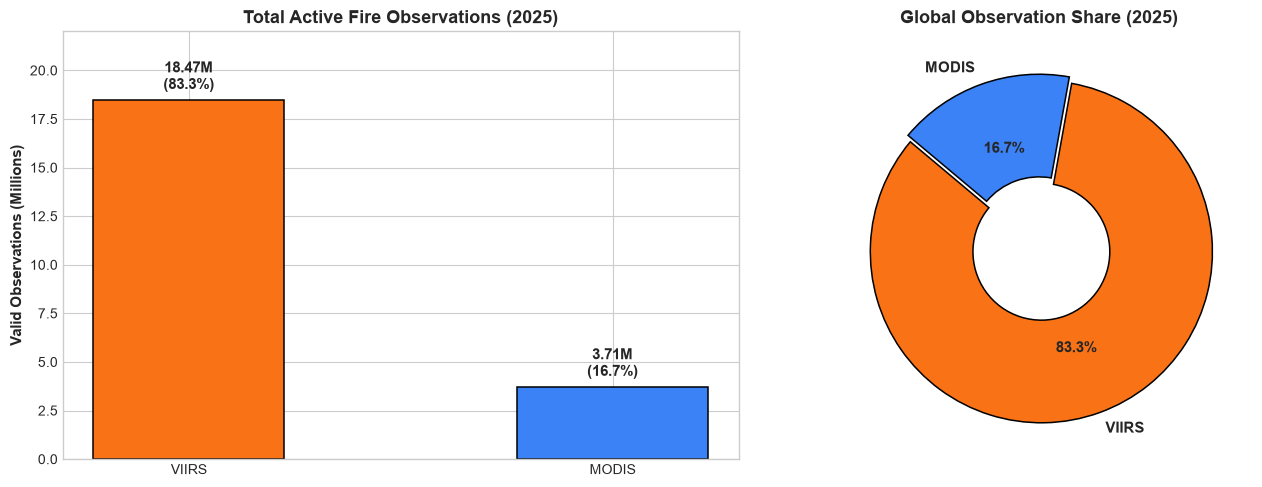

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#f97316', '#3b82f6']
bars = axes[0].bar(scale_df['instrument'], scale_df['valid_observations'] / 1e6, color=colors, width=0.45, edgecolor='black', linewidth=1.1)
axes[0].set_ylabel('Valid Observations (Millions)')
axes[0].set_title('Total Active Fire Observations (2025)')
axes[0].set_ylim(0, 22)
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 0.35, f'{yval:.2f}M\n({yval/22.175*100:.1f}%)', ha='center', va='bottom', fontweight='bold')

axes[1].pie(scale_df['valid_observations'], labels=scale_df['instrument'], colors=colors, autopct='%1.1f%%',
            startangle=140, explode=(0.04, 0), textprops={'fontsize': 11, 'fontweight': 'bold'},
            wedgeprops={'edgecolor': 'black', 'linewidth': 1.1, 'width': 0.6})
axes[1].set_title('Global Observation Share (2025)')

plt.tight_layout()
plt.show()


---
## 4. Complete Temporal Distribution Analysis

Active fires vary across diurnal, weekly, and seasonal timescales. Here we analyze:
1. Continuous 365-day daily trends.
2. 12-month seasonal cycles and monthly day/night splits.
3. Diurnal cycles: UTC hourly distribution vs. Estimated Local Solar Time (LST).
4. Day-of-week patterns.

### 4.1 Daily Observation Trend (365 Days of 2025)
We plot daily active-fire detections throughout 2025 to evaluate temporal continuity and identify seasonal fire pulses across sensors.

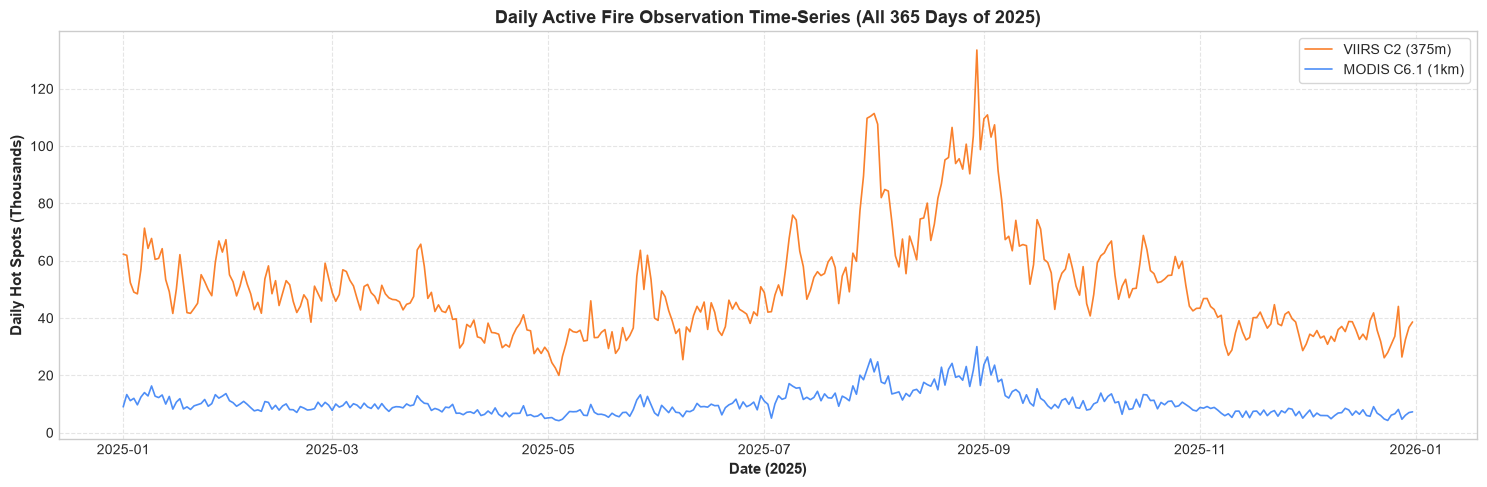

In [7]:
daily_df = con.execute('''
    SELECT 
        cast(acquisition_date as date) as date,
        SUM(CASE WHEN instrument = 'MODIS' THEN 1 ELSE 0 END) as modis_count,
        SUM(CASE WHEN instrument = 'VIIRS' THEN 1 ELSE 0 END) as viirs_count,
        COUNT(*) as total_count
    FROM unified
    WHERE is_valid = true
    GROUP BY date
    ORDER BY date
''').df()

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(daily_df['date'], daily_df['viirs_count'] / 1e3, color='#f97316', label='VIIRS C2 (375m)', linewidth=1.2, alpha=0.9)
ax.plot(daily_df['date'], daily_df['modis_count'] / 1e3, color='#3b82f6', label='MODIS C6.1 (1km)', linewidth=1.2, alpha=0.9)

ax.set_xlabel('Date (2025)')
ax.set_ylabel('Daily Hot Spots (Thousands)')
ax.set_title('Daily Active Fire Observation Time-Series (All 365 Days of 2025)')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(frameon=True, facecolor='white', loc='upper right')

plt.tight_layout()
plt.show()


### 4.2 Monthly Seasonality & Monthly Day/Night Breakdown
Fire activity peaks during regional dry seasons. We examine the monthly distribution and the daytime vs. nighttime detection share across each month.

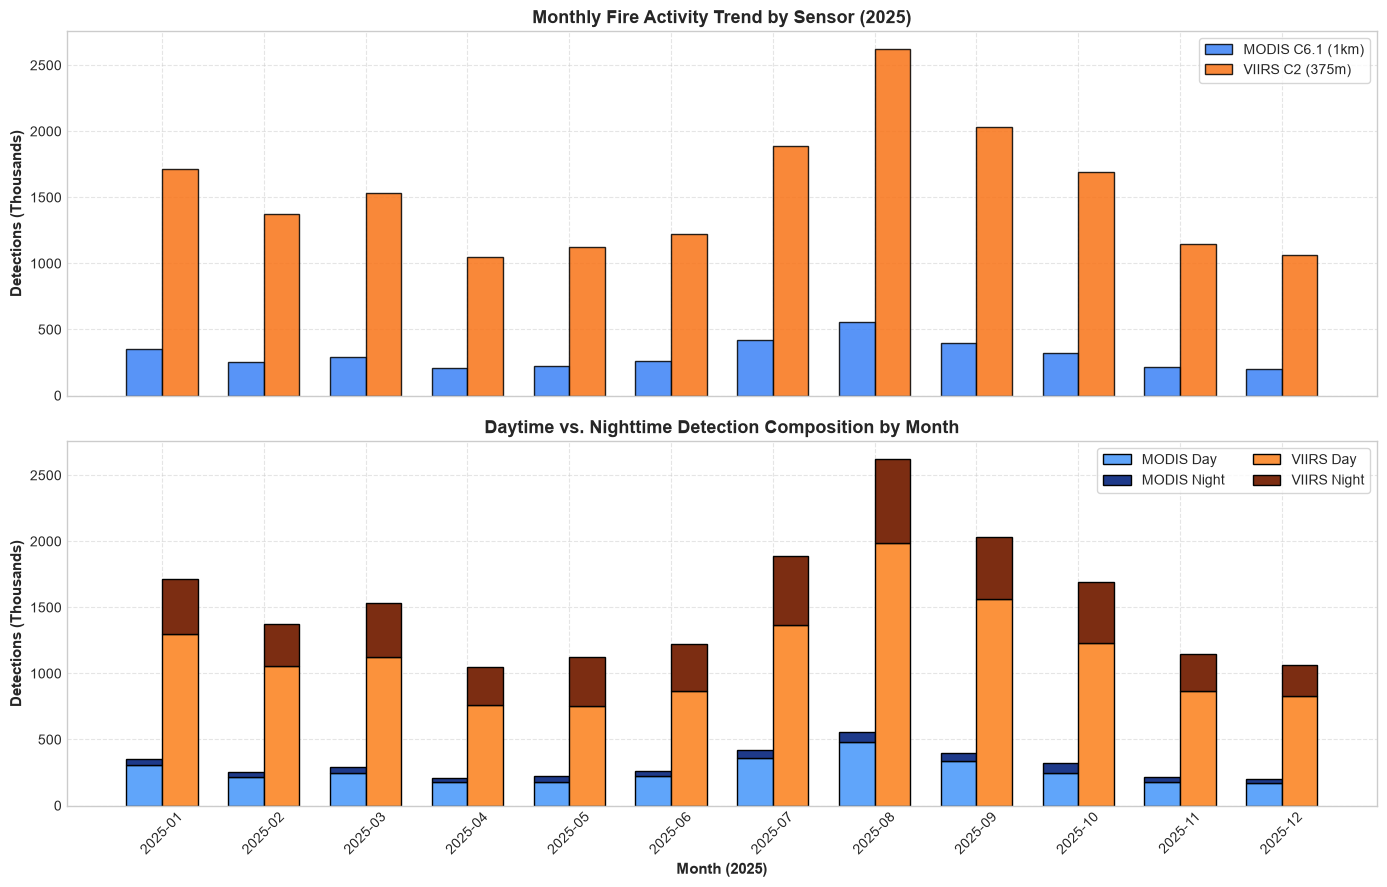

In [8]:
monthly_dn_df = con.execute('''
    SELECT 
        strftime(cast(acquisition_date as date), '%Y-%m') as month,
        SUM(CASE WHEN instrument = 'MODIS' AND daynight = 'D' THEN 1 ELSE 0 END) as modis_day,
        SUM(CASE WHEN instrument = 'MODIS' AND daynight = 'N' THEN 1 ELSE 0 END) as modis_night,
        SUM(CASE WHEN instrument = 'VIIRS' AND daynight = 'D' THEN 1 ELSE 0 END) as viirs_day,
        SUM(CASE WHEN instrument = 'VIIRS' AND daynight = 'N' THEN 1 ELSE 0 END) as viirs_night,
        COUNT(*) as total_month
    FROM unified
    WHERE is_valid = true
    GROUP BY month
    ORDER BY month
''').df()

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

x = np.arange(len(monthly_dn_df['month']))
width = 0.35

# Subplot 1: Sensor-wise Monthly Totals
axes[0].bar(x - width/2, (monthly_dn_df['modis_day'] + monthly_dn_df['modis_night']) / 1e3, width, label='MODIS C6.1 (1km)', color='#3b82f6', edgecolor='black', alpha=0.85)
axes[0].bar(x + width/2, (monthly_dn_df['viirs_day'] + monthly_dn_df['viirs_night']) / 1e3, width, label='VIIRS C2 (375m)', color='#f97316', edgecolor='black', alpha=0.85)
axes[0].set_ylabel('Detections (Thousands)')
axes[0].set_title('Monthly Fire Activity Trend by Sensor (2025)')
axes[0].legend(frameon=True, facecolor='white')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Day vs. Night Monthly Distribution
axes[1].bar(x - width/2, monthly_dn_df['modis_day'] / 1e3, width, label='MODIS Day', color='#60a5fa', edgecolor='black')
axes[1].bar(x - width/2, monthly_dn_df['modis_night'] / 1e3, width, bottom=monthly_dn_df['modis_day'] / 1e3, label='MODIS Night', color='#1e3a8a', edgecolor='black')
axes[1].bar(x + width/2, monthly_dn_df['viirs_day'] / 1e3, width, label='VIIRS Day', color='#fb923c', edgecolor='black')
axes[1].bar(x + width/2, monthly_dn_df['viirs_night'] / 1e3, width, bottom=monthly_dn_df['viirs_day'] / 1e3, label='VIIRS Night', color='#7c2d12', edgecolor='black')

axes[1].set_xlabel('Month (2025)')
axes[1].set_ylabel('Detections (Thousands)')
axes[1].set_title('Daytime vs. Nighttime Detection Composition by Month')
axes[1].set_xticks(x)
axes[1].set_xticklabels(monthly_dn_df['month'], rotation=45)
axes[1].legend(frameon=True, facecolor='white', ncol=2)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### 4.3 Diurnal Cycle: Global UTC vs. Estimated Local Solar Time (LST)

**Methodological Caveat on UTC Hourly Plots:**  
Plotting global fire counts against acquisition hour in UTC does **not** depict a local diurnal fire cycle. Because polar-orbiting satellites circle the globe while the Earth rotates, a detection at 13:00 UTC might occur at 15:00 local time in Eastern Europe, 16:00 in East Africa, or 06:00 in Central America. The peaks in a global UTC plot merely reflect when the satellite passed over the globe's most fire-dense landmasses.

**Local Solar Time Approximation:**  
To inspect actual local-time diurnal sampling, we compute an estimated Local Solar Time (LST) from longitude and UTC acquisition time:

$$\text{LST}_{\text{approx}} = \left(\text{UTC\_hour} + \frac{\text{UTC\_minute}}{60} + \frac{\text{longitude}}{15^\circ}\right) \pmod{24}$$

*Limitations of this approximation:* This calculation approximates mean solar time; it does not correct for the equation of time (which introduces variations up to $\pm 16\text{ minutes}$ over the year) or orbital tilt. However, it provides an appropriate first-order representation of local diurnal overpass timing.

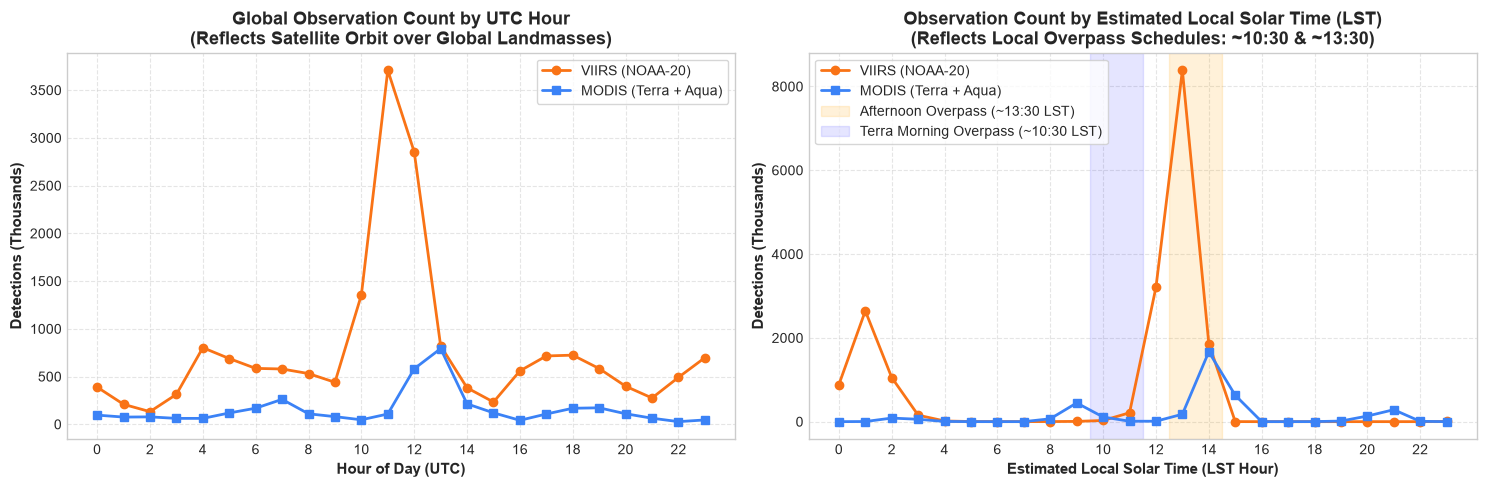

In [9]:
# Query UTC hourly distribution
hourly_utc_df = con.execute('''
    SELECT 
        CAST(extract(hour from acquisition_time) AS INTEGER) as hour_utc,
        SUM(CASE WHEN instrument = 'MODIS' THEN 1 ELSE 0 END) as modis_count,
        SUM(CASE WHEN instrument = 'VIIRS' THEN 1 ELSE 0 END) as viirs_count
    FROM unified
    WHERE is_valid = true AND acquisition_time IS NOT NULL
    GROUP BY hour_utc
    ORDER BY hour_utc
''').df()

# Query estimated Local Solar Time (LST) distribution
hourly_lst_df = con.execute('''
    SELECT 
        CAST(FLOOR(((extract(hour from acquisition_time) + extract(minute from acquisition_time)/60.0 + (longitude / 15.0)) % 24 + 24) % 24) AS INTEGER) AS lst_hour,
        SUM(CASE WHEN instrument = 'MODIS' THEN 1 ELSE 0 END) AS modis_count,
        SUM(CASE WHEN instrument = 'VIIRS' THEN 1 ELSE 0 END) AS viirs_count
    FROM unified
    WHERE is_valid = true AND acquisition_time IS NOT NULL
    GROUP BY lst_hour
    ORDER BY lst_hour
''').df()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: UTC Distribution
axes[0].plot(hourly_utc_df['hour_utc'], hourly_utc_df['viirs_count'] / 1e3, marker='o', color='#f97316', label='VIIRS (NOAA-20)', linewidth=2)
axes[0].plot(hourly_utc_df['hour_utc'], hourly_utc_df['modis_count'] / 1e3, marker='s', color='#3b82f6', label='MODIS (Terra + Aqua)', linewidth=2)
axes[0].set_xlabel('Hour of Day (UTC)')
axes[0].set_ylabel('Detections (Thousands)')
axes[0].set_title('Global Observation Count by UTC Hour\n(Reflects Satellite Orbit over Global Landmasses)')
axes[0].set_xticks(range(0, 24, 2))
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(frameon=True, facecolor='white')

# Subplot 2: Local Solar Time (LST) Distribution
axes[1].plot(hourly_lst_df['lst_hour'], hourly_lst_df['viirs_count'] / 1e3, marker='o', color='#f97316', label='VIIRS (NOAA-20)', linewidth=2)
axes[1].plot(hourly_lst_df['lst_hour'], hourly_lst_df['modis_count'] / 1e3, marker='s', color='#3b82f6', label='MODIS (Terra + Aqua)', linewidth=2)
axes[1].set_xlabel('Estimated Local Solar Time (LST Hour)')
axes[1].set_ylabel('Detections (Thousands)')
axes[1].set_title('Observation Count by Estimated Local Solar Time (LST)\n(Reflects Local Overpass Schedules: ~10:30 & ~13:30)')
axes[1].set_xticks(range(0, 24, 2))
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].axvspan(12.5, 14.5, color='orange', alpha=0.15, label='Afternoon Overpass (~13:30 LST)')
axes[1].axvspan(9.5, 11.5, color='blue', alpha=0.10, label='Terra Morning Overpass (~10:30 LST)')
axes[1].legend(frameon=True, facecolor='white')

plt.tight_layout()
plt.show()


### 4.4 Day-of-the-Week Distribution
We examine the distribution of observations across the days of the week (Monday through Sunday) to investigate whether human agricultural burn practices introduce weekly patterns.

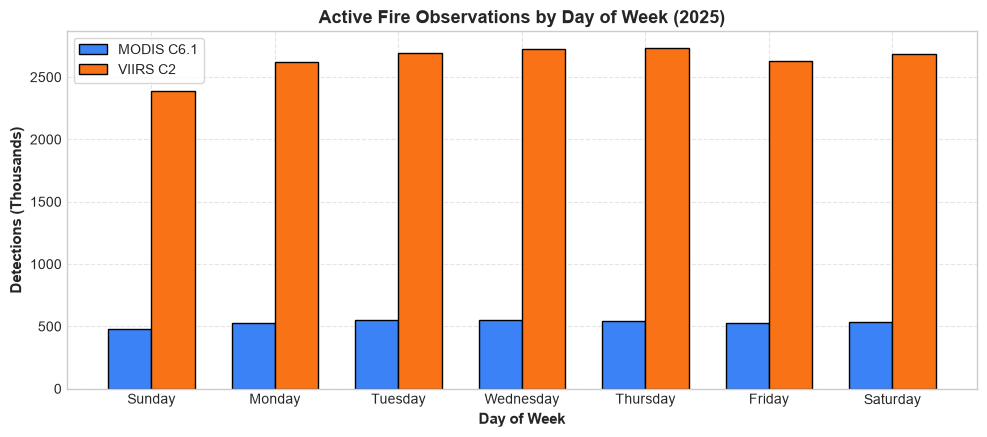

=== Day-of-Week Distribution Metrics ===
 day_name  modis_count  viirs_count  total_count
   Sunday     480043.0    2386547.0      2866590
   Monday     524173.0    2623222.0      3147395
  Tuesday     549423.0    2696454.0      3245877
Wednesday     548017.0    2724640.0      3272657
 Thursday     539656.0    2729095.0      3268751
   Friday     530031.0    2625474.0      3155505
 Saturday     537428.0    2681129.0      3218557


In [10]:
dow_df = con.execute('''
    SELECT 
        strftime(cast(acquisition_date as date), '%A') as day_name,
        extract(dow from cast(acquisition_date as date)) as dow_index,
        SUM(CASE WHEN instrument = 'MODIS' THEN 1 ELSE 0 END) as modis_count,
        SUM(CASE WHEN instrument = 'VIIRS' THEN 1 ELSE 0 END) as viirs_count,
        COUNT(*) as total_count
    FROM unified
    WHERE is_valid = true
    GROUP BY day_name, dow_index
    ORDER BY dow_index
''').df()

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(dow_df['day_name']))
width = 0.35

ax.bar(x - width/2, dow_df['modis_count'] / 1e3, width, label='MODIS C6.1', color='#3b82f6', edgecolor='black')
ax.bar(x + width/2, dow_df['viirs_count'] / 1e3, width, label='VIIRS C2', color='#f97316', edgecolor='black')

ax.set_xlabel('Day of Week')
ax.set_ylabel('Detections (Thousands)')
ax.set_title('Active Fire Observations by Day of Week (2025)')
ax.set_xticks(x)
ax.set_xticklabels(dow_df['day_name'])
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(frameon=True, facecolor='white')

plt.tight_layout()
plt.show()

print("=== Day-of-Week Distribution Metrics ===")
print(dow_df[['day_name', 'modis_count', 'viirs_count', 'total_count']].to_string(index=False))


---
## 5. Fire Radiative Power (FRP) Analysis — Physical Formulation

### 5.1 Physical Definition of FRP
Fire Radiative Power (FRP, measured in Megawatts, $\text{MW}$) represents the **instantaneous rate of radiant energy release** emitted by burning biomass at the time of satellite observation (Kaufman et al., 1998; Wooster et al., 2003, 2005):

$$FRP = \frac{A_{\text{pixel}} \cdot \sigma}{a} \left(L_4 - \bar{L}_{4,\text{bg}}\right)$$

Where:
- $A_{\text{pixel}}$ is the ground footprint area ($1.0\text{ km}^2$ for MODIS nadir; $0.14\text{ km}^2$ for VIIRS nadir).
- $L_4$ is the spectral radiance in the $4\,\mu\text{m}$ mid-infrared band.
- $\bar{L}_{4,\text{bg}}$ is the background radiance of surrounding non-fire pixels.
- $a$ is a sensor-specific response constant.
- $\sigma$ is the Stefan-Boltzmann constant.

### 5.2 Crucial Scientific Distinction: Power (MW) vs. Energy (MJ)
- **FRP is an instantaneous power rate ($1\text{ MW} = 10^6\text{ Joules/second}$).**
- Summing instantaneous FRP observations across a year computes the **sum of reported snapshot FRP values ($\sum \text{FRP}$ in MW)**.
- Summing snapshot FRP values does **NOT** compute total Fire Radiative Energy (FRE in Joules or Megajoules). Calculating total energy requires continuous temporal integration over the fire's burn duration ($\text{FRE} = \int \text{FRP}(t)\,dt$), which polar-orbiting satellites with only 1–2 snapshots per day cannot compute without external geostationary diurnal modeling.
- The similarity between the total summed FRP of MODIS ($152.8\text{M MW}$) and VIIRS ($178.8\text{M MW}$) does **not** prove physical energy conservation or convergence; it is an empirical consequence of spatial sampling, pixel splitting, and minimum detection thresholds.

In [11]:
frp_stats_df = con.execute('''
    SELECT 
        instrument,
        COUNT(*) as observation_count,
        ROUND(MIN(frp), 2) as min_frp,
        ROUND(QUANTILE_CONT(frp, 0.25), 2) as q25,
        ROUND(MEDIAN(frp), 2) as median_frp,
        ROUND(QUANTILE_CONT(frp, 0.75), 2) as q75,
        ROUND(QUANTILE_CONT(frp, 0.95), 2) as q95,
        ROUND(QUANTILE_CONT(frp, 0.99), 2) as q99,
        ROUND(MAX(frp), 2) as max_frp,
        ROUND(AVG(frp), 2) as mean_frp,
        ROUND(STDDEV_SAMP(frp), 2) as std_frp,
        ROUND(SUM(frp) / 1e6, 2) as sum_reported_frp_million_mw
    FROM unified
    WHERE is_valid = true AND frp >= 0
    GROUP BY instrument
''').df()

print("=== Parametric and Non-Parametric FRP Statistics (Valid Records, FRP >= 0) ===")
print(frp_stats_df.to_string(index=False))


=== Parametric and Non-Parametric FRP Statistics (Valid Records, FRP >= 0) ===
instrument  observation_count  min_frp   q25  median_frp   q75    q95    q99  max_frp  mean_frp  std_frp  sum_reported_frp_million_mw
     MODIS            3708771      0.0 10.10       17.90 37.10 130.30 391.10 11247.10     41.21   113.47                       152.82
     VIIRS           18466561      0.0  2.62        5.05  9.45  30.75  88.62  3907.87      9.68    20.39                       178.84


### 5.3 Sensor Resolution & Thermal Dilution: Why MODIS Mean FRP is Higher
The table demonstrates that MODIS mean FRP is **$4.25\times$ higher** ($41.21\text{ MW}$ vs. $9.68\text{ MW}$), and its median is **$3.54\times$ higher** ($17.9\text{ MW}$ vs. $5.05\text{ MW}$).

**Crucial Scientific Interpretation:**  
A higher mean FRP for MODIS does **not** mean MODIS observed more intense physical fires. Rather, it reflects **sub-pixel thermal dilution** and differing instrument detection thresholds:
- In a $1\text{ km}^2$ MODIS footprint, small fires emitting $\le 5\text{ MW}$ fail to elevate the pixel's average mid-infrared brightness temperature sufficiently above background noise, leaving them undetected; the 50% detection probability threshold is $\approx 8\text{--}10\text{ MW}$ under standard atmospheric conditions (Giglio et al., 2003, 2016).
- In a $0.14\text{ km}^2$ VIIRS footprint, the same small fire occupies a $7.1\times$ larger fraction of the pixel area, producing a strong thermal contrast and triggering detection down to $\approx 0.5\text{--}1.0\text{ MW}$ (Schroeder et al., 2014, Section 4.2).
- Furthermore, a single large wildfire that triggers one MODIS pixel at $50\text{ MW}$ is resolved by VIIRS as multiple adjacent 375m pixels. As an illustrative geometric example, a contiguous flaming front might be detected as five VIIRS pixels averaging $\sim 10\text{ MW}$ each; note that this 1:5 ratio is an illustrative example of spatial splitting rather than a universal empirical rule.

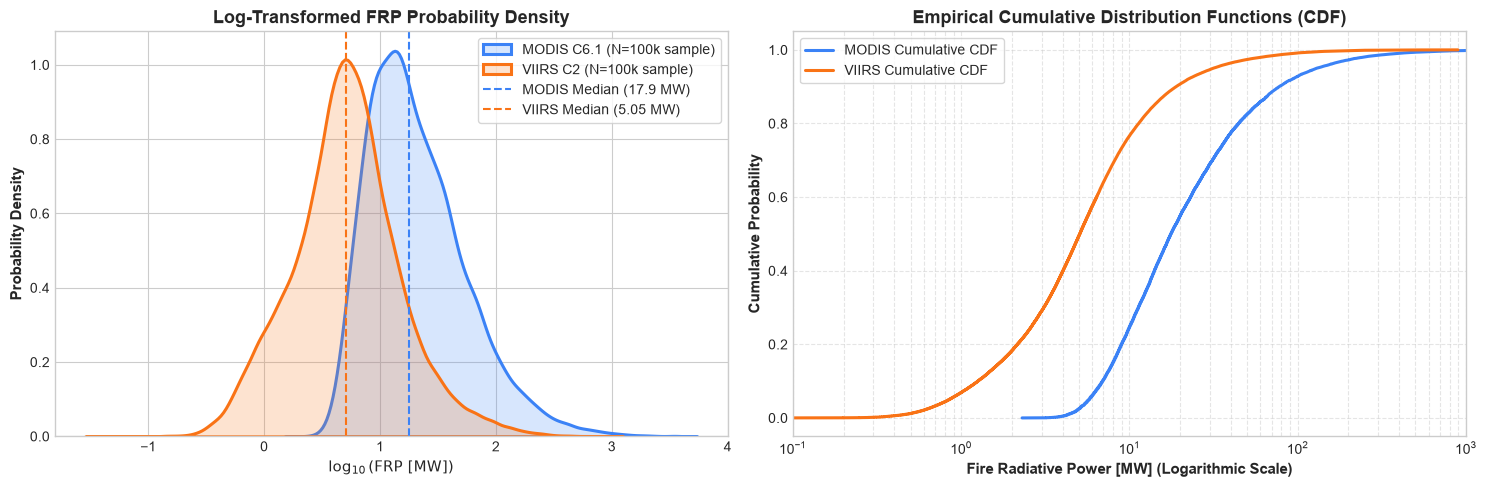

In [12]:
# Sample N = 100,000 valid observations per sensor for rapid, high-fidelity KDE estimation
modis_sample = con.execute("SELECT frp FROM unified WHERE instrument = 'MODIS' AND is_valid = true AND frp > 0 USING SAMPLE 100000").df()
viirs_sample = con.execute("SELECT frp FROM unified WHERE instrument = 'VIIRS' AND is_valid = true AND frp > 0 USING SAMPLE 100000").df()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Log-scale KDE Distribution
sns.kdeplot(np.log10(modis_sample['frp']), ax=axes[0], color='#3b82f6', label='MODIS C6.1 (N=100k sample)', linewidth=2.2, fill=True, alpha=0.2)
sns.kdeplot(np.log10(viirs_sample['frp']), ax=axes[0], color='#f97316', label='VIIRS C2 (N=100k sample)', linewidth=2.2, fill=True, alpha=0.2)
axes[0].set_xlabel(r'$\log_{10}(\text{FRP [MW]})$')
axes[0].set_ylabel('Probability Density')
axes[0].set_title('Log-Transformed FRP Probability Density')
axes[0].axvline(np.log10(17.9), color='#3b82f6', linestyle='--', label='MODIS Median (17.9 MW)')
axes[0].axvline(np.log10(5.05), color='#f97316', linestyle='--', label='VIIRS Median (5.05 MW)')
axes[0].legend(frameon=True, facecolor='white')

# Subplot 2: Empirical Cumulative Distribution Function (CDF)
sorted_modis = np.sort(modis_sample['frp'])
p_modis = 1.0 * np.arange(len(modis_sample)) / (len(modis_sample) - 1)
sorted_viirs = np.sort(viirs_sample['frp'])
p_viirs = 1.0 * np.arange(len(viirs_sample)) / (len(viirs_sample) - 1)

axes[1].plot(sorted_modis, p_modis, color='#3b82f6', linewidth=2.2, label='MODIS Cumulative CDF')
axes[1].plot(sorted_viirs, p_viirs, color='#f97316', linewidth=2.2, label='VIIRS Cumulative CDF')
axes[1].set_xscale('log')
axes[1].set_xlim(0.1, 1000)
axes[1].set_xlabel('Fire Radiative Power [MW] (Logarithmic Scale)')
axes[1].set_ylabel('Cumulative Probability')
axes[1].set_title('Empirical Cumulative Distribution Functions (CDF)')
axes[1].grid(True, which='both', linestyle='--', alpha=0.5)
axes[1].legend(frameon=True, facecolor='white')

plt.tight_layout()
plt.show()


### 5.4 FRP Power Bin Distribution
We inspect counts across standardized logarithmic power bins to reveal the empirical distribution of observations.

=== FRP Binned Power Breakdown ===
  bin_label  modis_count  viirs_count
     0-5 MW      84755.0    9148367.0
    5-10 MW     821331.0    5021802.0
   10-25 MW    1416741.0    3060075.0
   25-50 MW     728624.0     778988.0
  50-100 MW     389725.0     307653.0
 100-250 MW     194893.0     129612.0
 250-500 MW      47266.0      18140.0
500-1000 MW      17311.0       1791.0
   1000+ MW       8125.0        133.0


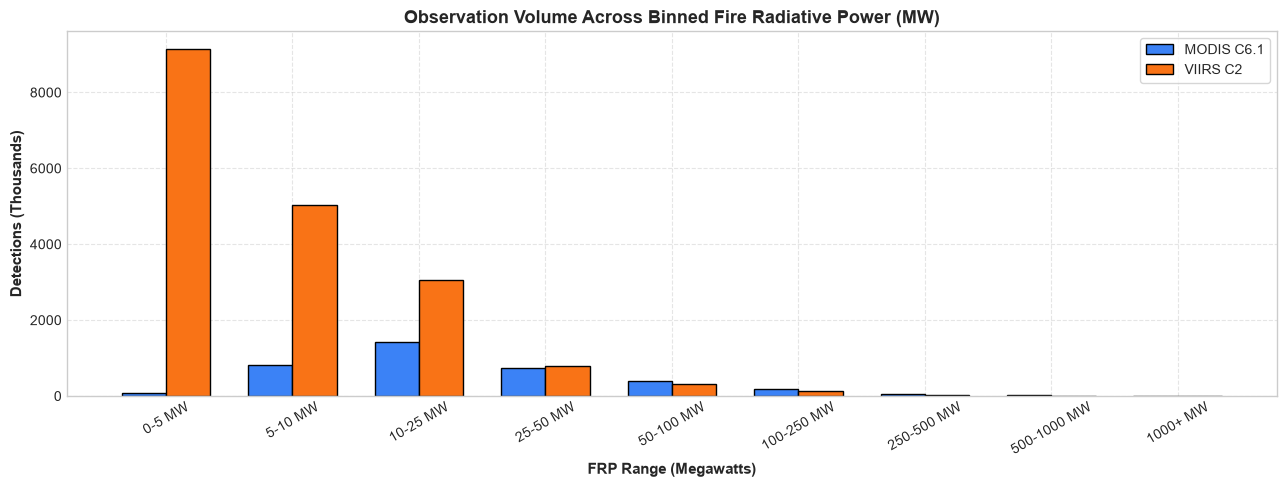

In [13]:
bins_df = con.execute('''
    SELECT 
        CASE 
            WHEN frp < 5 THEN '0-5 MW'
            WHEN frp < 10 THEN '5-10 MW'
            WHEN frp < 25 THEN '10-25 MW'
            WHEN frp < 50 THEN '25-50 MW'
            WHEN frp < 100 THEN '50-100 MW'
            WHEN frp < 250 THEN '100-250 MW'
            WHEN frp < 500 THEN '250-500 MW'
            WHEN frp < 1000 THEN '500-1000 MW'
            ELSE '1000+ MW'
        END as bin_label,
        CASE 
            WHEN frp < 5 THEN 1
            WHEN frp < 10 THEN 2
            WHEN frp < 25 THEN 3
            WHEN frp < 50 THEN 4
            WHEN frp < 100 THEN 5
            WHEN frp < 250 THEN 6
            WHEN frp < 500 THEN 7
            WHEN frp < 1000 THEN 8
            ELSE 9
        END as bin_order,
        SUM(CASE WHEN instrument = 'MODIS' THEN 1 ELSE 0 END) as modis_count,
        SUM(CASE WHEN instrument = 'VIIRS' THEN 1 ELSE 0 END) as viirs_count
    FROM unified
    WHERE is_valid = true AND frp >= 0
    GROUP BY bin_label, bin_order
    ORDER BY bin_order
''').df()

print("=== FRP Binned Power Breakdown ===")
print(bins_df[['bin_label', 'modis_count', 'viirs_count']].to_string(index=False))

fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(bins_df['bin_label']))
width = 0.35

ax.bar(x - width/2, bins_df['modis_count'] / 1e3, width, label='MODIS C6.1', color='#3b82f6', edgecolor='black')
ax.bar(x + width/2, bins_df['viirs_count'] / 1e3, width, label='VIIRS C2', color='#f97316', edgecolor='black')

ax.set_xlabel('FRP Range (Megawatts)')
ax.set_ylabel('Detections (Thousands)')
ax.set_title('Observation Volume Across Binned Fire Radiative Power (MW)')
ax.set_xticks(x)
ax.set_xticklabels(bins_df['bin_label'], rotation=30)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(frameon=True, facecolor='white')

plt.tight_layout()
plt.show()


---
## 6. Brightness Temperature Analysis & Sensor Saturation

Active fire detection algorithms evaluate the mid-infrared $4\,\mu\text{m}$ channel against ambient background conditions. Blackbody spectral radiance follows Planck's Law:

$$B(\lambda, T) = \frac{2hc^2}{\lambda^5 \left(e^{\frac{hc}{\lambda k_B T}} - 1\right)}$$

At active combustion temperatures ($T \approx 600\text{--}1200\text{ K}$), the peak of thermal emission shifts toward the $4\,\mu\text{m}$ window (Wien's displacement law).

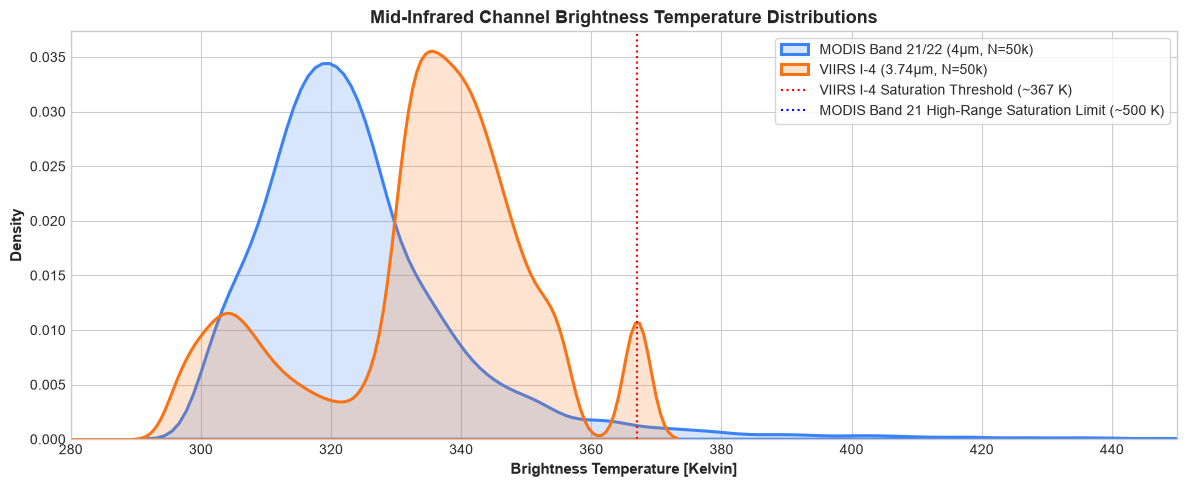

In [14]:
# Sample brightness temperatures (N = 50,000 per sensor)
modis_bt = con.execute("SELECT brightness FROM unified WHERE instrument = 'MODIS' AND is_valid = true AND brightness > 250 USING SAMPLE 50000").df()
viirs_bt = con.execute("SELECT brightness FROM unified WHERE instrument = 'VIIRS' AND is_valid = true AND brightness > 250 USING SAMPLE 50000").df()

fig, ax = plt.subplots(figsize=(12, 5))
sns.kdeplot(modis_bt['brightness'], ax=ax, color='#3b82f6', label='MODIS Band 21/22 (4µm, N=50k)', linewidth=2.2, fill=True, alpha=0.2)
sns.kdeplot(viirs_bt['brightness'], ax=ax, color='#f97316', label='VIIRS I-4 (3.74µm, N=50k)', linewidth=2.2, fill=True, alpha=0.2)

ax.set_xlabel('Brightness Temperature [Kelvin]')
ax.set_ylabel('Density')
ax.set_title('Mid-Infrared Channel Brightness Temperature Distributions')
ax.axvline(367, color='red', linestyle=':', label='VIIRS I-4 Saturation Threshold (~367 K)')
ax.axvline(500, color='blue', linestyle=':', label='MODIS Band 21 High-Range Saturation Limit (~500 K)')
ax.legend(frameon=True, facecolor='white')
ax.set_xlim(280, 450)

plt.tight_layout()
plt.show()


---
## 7. Complete Geographical Distribution & Spatial Clustering

### 7.1 The 2-Degree Spatial Density Grid & Area Distortion Caveat
To inspect global distributions across 22.18M records without rendering millions of individual vector points, we aggregate observations onto a standardized **2-degree equirectangular grid**:

$$\text{lat\_bin} = \left\lfloor\frac{\text{latitude}}{2^\circ}\right\rfloor \times 2^\circ, \quad \text{lon\_bin} = \left\lfloor\frac{\text{longitude}}{2^\circ}\right\rfloor \times 2^\circ$$

**Poleward Area Distortion Caveat:**  
On an equirectangular projection, the geographic ground area of a $2^\circ \times 2^\circ$ cell varies with latitude:

$$\text{Area}(\phi) \approx (2 \times 111.13\text{ km}) \times (2 \times 111.13\text{ km} \times \cos\phi) \approx 49,400 \cdot \cos\phi \text{ km}^2$$

- At the Equator ($\phi = 0^\circ$): cell area is $\approx 49,400\text{ km}^2$.
- In the Subtropics ($\phi = 30^\circ$): cell area is $\approx 42,780\text{ km}^2$ (13% smaller).
- In the Boreal Zone ($\phi = 60^\circ$): cell area is $\approx 24,700\text{ km}^2$ (**50% smaller**).

Consequently, high raw observation counts in polar/boreal zones represent higher spatial densities per unit ground area than equivalent counts near the equator.

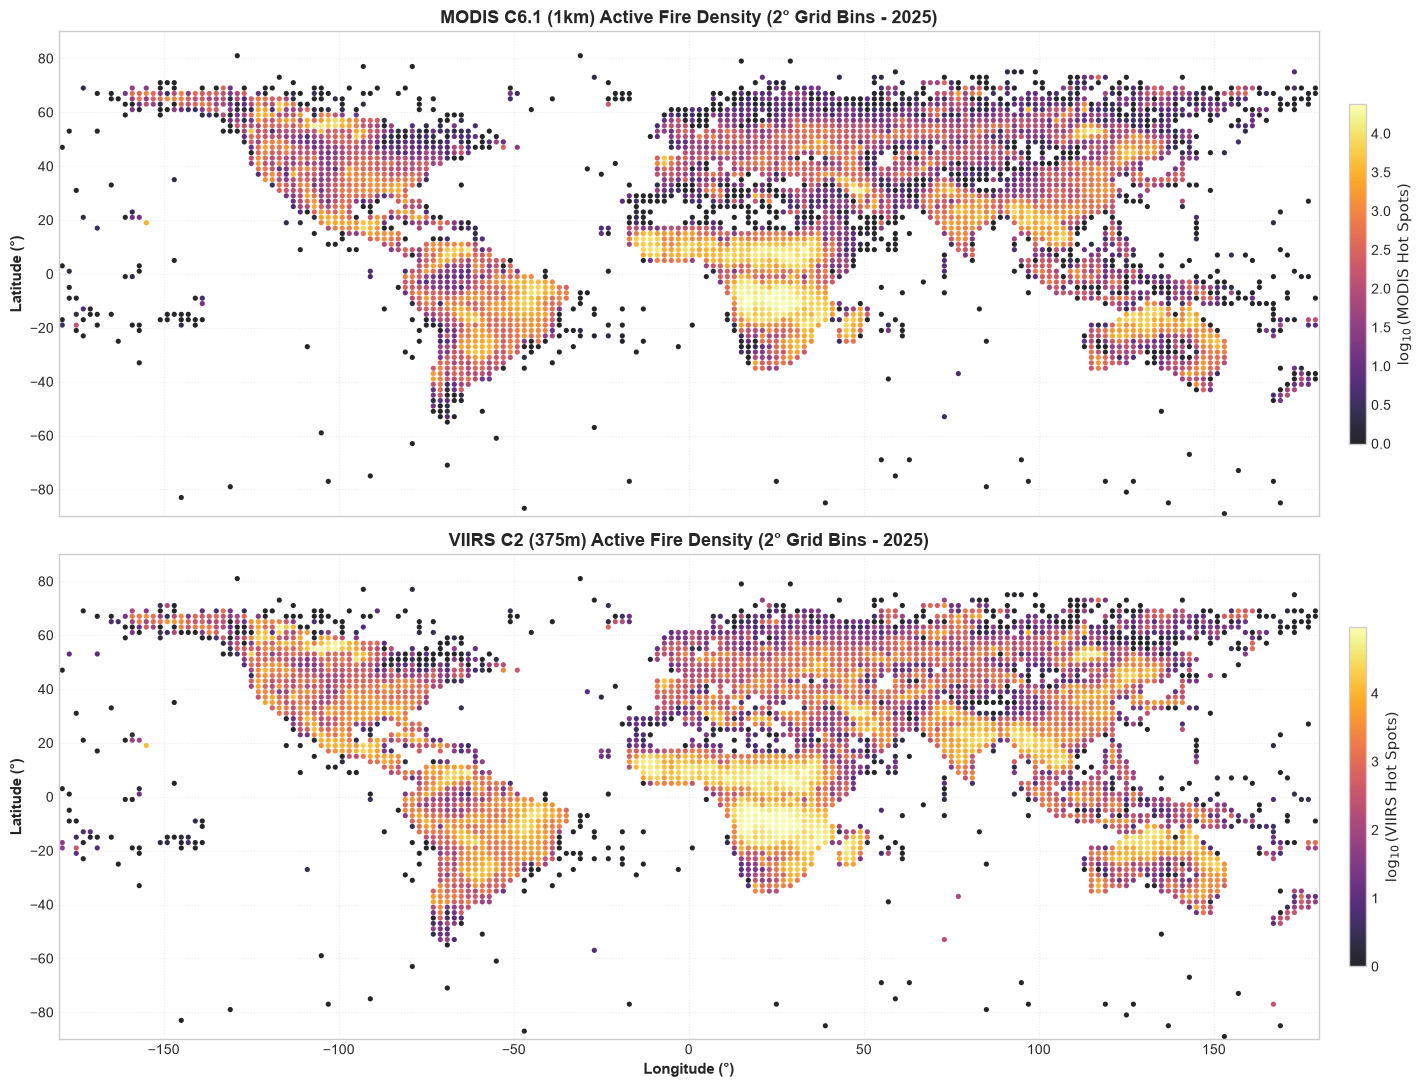

In [15]:
# 7.2 Sensor-Specific Spatial Density Mapping
grid_sensor_df = con.execute('''
    SELECT 
        CAST(FLOOR(latitude / 2.0) * 2.0 AS DOUBLE) as lat_bin,
        CAST(FLOOR(longitude / 2.0) * 2.0 AS DOUBLE) as lon_bin,
        SUM(CASE WHEN instrument = 'MODIS' THEN 1 ELSE 0 END) as modis_count,
        SUM(CASE WHEN instrument = 'VIIRS' THEN 1 ELSE 0 END) as viirs_count,
        COUNT(*) as total_count
    FROM unified
    WHERE is_valid = true
    GROUP BY lat_bin, lon_bin
''').df()

fig, axes = plt.subplots(2, 1, figsize=(16, 11), sharex=True)

# Subplot 1: MODIS 2° Density
scatter_modis = axes[0].scatter(
    grid_sensor_df['lon_bin'] + 1.0, 
    grid_sensor_df['lat_bin'] + 1.0, 
    c=np.log10(np.maximum(1, grid_sensor_df['modis_count'])), 
    cmap='inferno', s=14, alpha=0.85, edgecolors='none'
)
cbar0 = plt.colorbar(scatter_modis, ax=axes[0], orientation='vertical', shrink=0.7, pad=0.02)
cbar0.set_label(r'$\log_{10}(\text{MODIS Hot Spots})$', fontweight='bold')
axes[0].set_ylim(-90, 90)
axes[0].set_ylabel('Latitude (°)')
axes[0].set_title('MODIS C6.1 (1km) Active Fire Density (2° Grid Bins - 2025)')
axes[0].grid(True, linestyle=':', alpha=0.4)

# Subplot 2: VIIRS 2° Density
scatter_viirs = axes[1].scatter(
    grid_sensor_df['lon_bin'] + 1.0, 
    grid_sensor_df['lat_bin'] + 1.0, 
    c=np.log10(np.maximum(1, grid_sensor_df['viirs_count'])), 
    cmap='inferno', s=14, alpha=0.85, edgecolors='none'
)
cbar1 = plt.colorbar(scatter_viirs, ax=axes[1], orientation='vertical', shrink=0.7, pad=0.02)
cbar1.set_label(r'$\log_{10}(\text{VIIRS Hot Spots})$', fontweight='bold')
axes[1].set_xlim(-180, 180)
axes[1].set_ylim(-90, 90)
axes[1].set_xlabel('Longitude (°)')
axes[1].set_ylabel('Latitude (°)')
axes[1].set_title('VIIRS C2 (375m) Active Fire Density (2° Grid Bins - 2025)')
axes[1].grid(True, linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()


### 7.3 Top Density Regions Identified by Coordinate Bounds
We identify the top 10 most active 2-degree grid cells globally by their exact latitude/longitude coordinate bounds.

*Documentation Note on Country Boundaries:* National polygon boundary shapefiles are not bundled into this lightweight data pipeline; therefore, cells are strictly designated by coordinate bounds rather than unverified national labels.

In [16]:
top10_cells = con.execute('''
    SELECT 
        lat_bin,
        lat_bin + 2.0 as lat_max,
        lon_bin,
        lon_bin + 2.0 as lon_max,
        SUM(CASE WHEN instrument = 'MODIS' THEN 1 ELSE 0 END) as modis_count,
        SUM(CASE WHEN instrument = 'VIIRS' THEN 1 ELSE 0 END) as viirs_count,
        COUNT(*) as total_count,
        ROUND(AVG(frp), 2) as mean_frp_mw,
        ROUND(SUM(frp) / 1e3, 2) as sum_frp_gw
    FROM (
        SELECT 
            FLOOR(latitude / 2.0) * 2.0 as lat_bin,
            FLOOR(longitude / 2.0) * 2.0 as lon_bin,
            instrument,
            frp
        FROM unified
        WHERE is_valid = true
    )
    GROUP BY lat_bin, lon_bin
    ORDER BY total_count DESC
    LIMIT 10
''').df()

print("=== Top 10 Most Active 2-Degree Grid Cells (2025) ===")
print(top10_cells.to_string(index=False))


=== Top 10 Most Active 2-Degree Grid Cells (2025) ===
 lat_bin  lat_max  lon_bin  lon_max  modis_count  viirs_count  total_count  mean_frp_mw  sum_frp_gw
   -10.0     -8.0     16.0     18.0      22954.0      92637.0       115591        20.44     2363.14
   -12.0    -10.0     16.0     18.0      23393.0      91485.0       114878        15.52     1782.67
   -12.0    -10.0     26.0     28.0      23838.0      90352.0       114190        13.45     1535.75
    30.0     32.0     46.0     48.0      21268.0      90031.0       111299        14.17     1577.59
    -8.0     -6.0     26.0     28.0      19846.0      84981.0       104827        16.71     1752.06
   -10.0     -8.0     22.0     24.0      22839.0      81177.0       104016        25.13     2613.93
   -12.0    -10.0     28.0     30.0      20072.0      83101.0       103173        14.11     1455.42
   -14.0    -12.0     26.0     28.0      21185.0      80702.0       101887        13.88     1414.33
    -6.0     -4.0     18.0     20.0      15127

### 7.4 Latitudinal Distribution Profile (5° Bands)
We aggregate observations into 5-degree latitudinal bands to identify global fire belts.

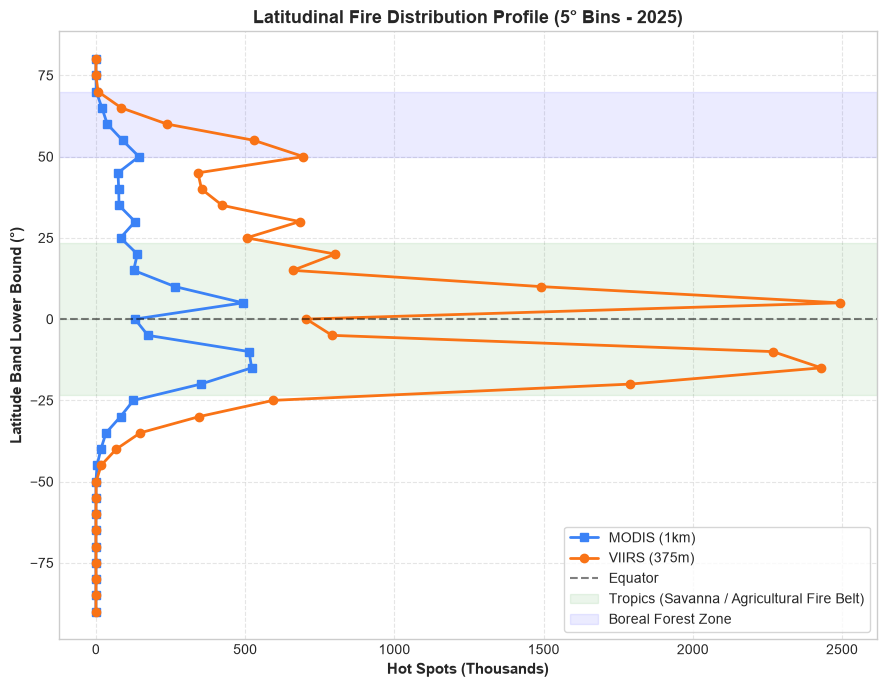

In [17]:
lat_bands_df = con.execute('''
    SELECT 
        CAST(FLOOR(latitude / 5.0) * 5.0 AS INTEGER) as lat_band,
        SUM(CASE WHEN instrument = 'MODIS' THEN 1 ELSE 0 END) as modis_count,
        SUM(CASE WHEN instrument = 'VIIRS' THEN 1 ELSE 0 END) as viirs_count
    FROM unified
    WHERE is_valid = true
    GROUP BY lat_band
    ORDER BY lat_band
''').df()

fig, ax = plt.subplots(figsize=(9, 7))
ax.plot(lat_bands_df['modis_count'] / 1e3, lat_bands_df['lat_band'], marker='s', color='#3b82f6', label='MODIS (1km)', linewidth=2)
ax.plot(lat_bands_df['viirs_count'] / 1e3, lat_bands_df['lat_band'], marker='o', color='#f97316', label='VIIRS (375m)', linewidth=2)

ax.set_xlabel('Hot Spots (Thousands)')
ax.set_ylabel('Latitude Band Lower Bound (°)')
ax.set_title('Latitudinal Fire Distribution Profile (5° Bins - 2025)')
ax.axhline(0, color='black', linestyle='--', alpha=0.5, label='Equator')
ax.axhspan(-23.5, 23.5, color='green', alpha=0.08, label='Tropics (Savanna / Agricultural Fire Belt)')
ax.axhspan(50, 70, color='blue', alpha=0.08, label='Boreal Forest Zone')
ax.legend(frameon=True, facecolor='white', loc='lower right')
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


---
## 8. Separate Sensor Confidence Analysis & Conventions

### 8.1 Methodological Requirement: Preserving Native Conventions
A common analytical error in multi-sensor fire studies is mapping MODIS numeric confidence directly to VIIRS categorical flags. These two metrics represent entirely different algorithmic conventions:
- **MODIS C6.1:** Outputs a continuous score from **$0\%$ to $100\%$**, computed from cloud proximity, view zenith angle, and contextual thermal contrast against surrounding background pixels.
- **VIIRS C2:** Outputs discrete categorical flags:
  - `'l'` (low): Marginal detection, potential sub-pixel glint or cloud-edge artifact.
  - `'n'` (nominal): Highly confident fire under standard atmospheric conditions.
  - `'h'` (high): Saturated $4\,\mu\text{m}$ detection channel or clear nighttime thermal anomaly.

**Scientific Principle:** MODIS numeric confidence and VIIRS categorical flags must be analyzed separately within their native conventions.

MODIS Numeric Confidence: Mean = 66.47%, Median = 68.0%, IQR = [54.0%, 81.0%]



=== VIIRS Categorical Confidence Distribution ===
conf_flag    count   pct
        n 15319514 82.96
        l  2220253 12.02
        h   926794  5.02


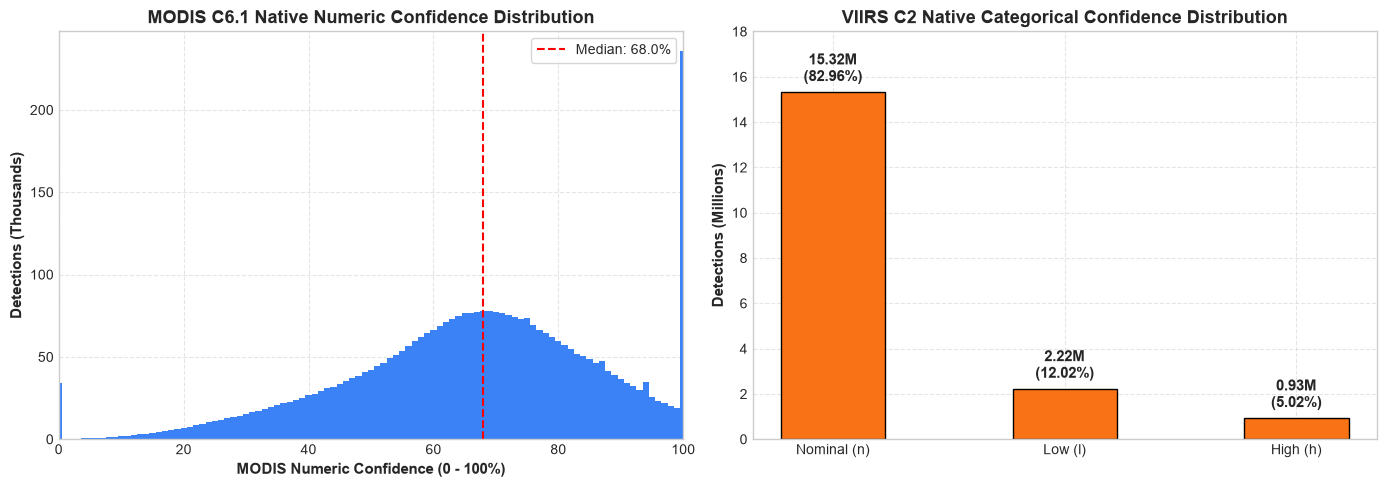

In [18]:
# 8.2 MODIS Numeric Confidence Distribution (0 - 100%)
modis_conf_df = con.execute('''
    SELECT 
        TRY_CAST(confidence AS INTEGER) as conf_numeric,
        COUNT(*) as count
    FROM unified
    WHERE instrument = 'MODIS' AND is_valid = true
    GROUP BY conf_numeric
    ORDER BY conf_numeric
''').df()

modis_conf_stats = con.execute('''
    SELECT 
        ROUND(AVG(TRY_CAST(confidence AS INTEGER)), 2) as mean_conf,
        ROUND(MEDIAN(TRY_CAST(confidence AS INTEGER)), 2) as median_conf,
        ROUND(QUANTILE_CONT(TRY_CAST(confidence AS INTEGER), 0.25), 2) as q25_conf,
        ROUND(QUANTILE_CONT(TRY_CAST(confidence AS INTEGER), 0.75), 2) as q75_conf
    FROM unified
    WHERE instrument = 'MODIS' AND is_valid = true
''').fetchone()

print(f"MODIS Numeric Confidence: Mean = {modis_conf_stats[0]}%, Median = {modis_conf_stats[1]}%, IQR = [{modis_conf_stats[2]}%, {modis_conf_stats[3]}%]")

# 8.3 VIIRS Categorical Confidence Distribution (l, n, h)
viirs_conf_df = con.execute('''
    SELECT 
        confidence as conf_flag,
        COUNT(*) as count,
        ROUND(COUNT(*) * 100.0 / (SELECT COUNT(*) FROM unified WHERE instrument = 'VIIRS' AND is_valid = true), 2) as pct
    FROM unified
    WHERE instrument = 'VIIRS' AND is_valid = true
    GROUP BY conf_flag
    ORDER BY count DESC
''').df()

print("\n=== VIIRS Categorical Confidence Distribution ===")
print(viirs_conf_df.to_string(index=False))

# Plotting Separate Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: MODIS Continuous Histogram
axes[0].bar(modis_conf_df['conf_numeric'], modis_conf_df['count'] / 1e3, color='#3b82f6', width=1.0, edgecolor='none')
axes[0].axvline(modis_conf_stats[1], color='red', linestyle='--', label=f'Median: {modis_conf_stats[1]}%')
axes[0].set_xlabel('MODIS Numeric Confidence (0 - 100%)')
axes[0].set_ylabel('Detections (Thousands)')
axes[0].set_title('MODIS C6.1 Native Numeric Confidence Distribution')
axes[0].set_xlim(0, 100)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(frameon=True, facecolor='white')

# Subplot 2: VIIRS Categorical Bar Chart
viirs_labels = {'n': 'Nominal (n)', 'l': 'Low (l)', 'h': 'High (h)'}
bars_v = axes[1].bar([viirs_labels.get(f, f) for f in viirs_conf_df['conf_flag']], viirs_conf_df['count'] / 1e6, color='#f97316', width=0.45, edgecolor='black')
axes[1].set_ylabel('Detections (Millions)')
axes[1].set_title('VIIRS C2 Native Categorical Confidence Distribution')
axes[1].set_ylim(0, 18)
for bar, pct in zip(bars_v, viirs_conf_df['pct']):
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f'{yval:.2f}M\n({pct}%)', ha='center', va='bottom', fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### 8.4 Analyst-Defined Exploratory Binning (Explicitly Non-Equivalent)
For exploratory dashboards, analysts sometimes bin MODIS confidence into:
- Low: $< 30\%$
- Nominal: $30\%\text{--}79\%$
- High: $\ge 80\%$

**Clear Methodological Limitation:**  
These bins are **analyst-defined exploratory categories**. They do **not** calibrate or establish equivalence to VIIRS `'l'`, `'n'`, `'h'` classes. VIIRS flags are produced by internal algorithm thresholds (e.g., day vs. night contextual tests), while MODIS scores reflect an empirical probability estimate.

---
## 9. Multi-Sensor Discrepancy & Footprint Geometry Analysis

### 9.1 The Physical Roots of Observation Disparity
Why does VIIRS detect $\approx 5\times$ more active-fire observations than MODIS?

| Physical / Instrument Factor | MODIS (Terra / Aqua) | VIIRS (NOAA-20 / JPSS-1) | Quantitative Impact | Authoritative Reference |
| :--- | :--- | :--- | :--- | :--- |
| **Nadir Spatial Resolution** | $1,000\text{ m} \times 1,000\text{ m}$ ($1.0\text{ km}^2$) | $375\text{ m} \times 375\text{ m}$ ($0.14\text{ km}^2$) | VIIRS resolves sub-pixel fires $7.11\times$ smaller in ground area. | Giglio et al. (2016), Schroeder et al. (2014) |
| **Scan Edge Footprint** | Expands to $\approx 2,000\text{ m} \times 4,800\text{ m}$ ($\approx 9.6\text{ km}^2$) | Expands only to $\approx 800\text{ m} \times 800\text{ m}$ ($\approx 0.64\text{ km}^2$) | Pixel growth constrained 15-fold by onboard aggregation. | Wolfe et al. (2002), Schroeder et al. (2014) |
| **Detection Threshold** | $FRP_{50\%} \ge 8\text{--}10\text{ MW}$ | $FRP_{\text{min}} \ge 0.5\text{--}1.0\text{ MW}$ | VIIRS detects small, cooler smoldering fires. | Giglio et al. (2003, 2016), Schroeder et al. (2014) |
| **Swath Width** | $2,330\text{ km}$ (equatorial orbit gaps) | $3,040\text{ km}$ (zero orbital gaps) | VIIRS achieves full contiguous equatorial coverage daily. | NASA FIRMS Documentation |
| **Pixel Overlap Handling** | High cross-scan overlap at scan edge | Onboard deletion of overlapping samples | Prevents artificial duplicate detections. | Wolfe et al. (2002), Schroeder et al. (2014) |

**Illustrative Sub-Pixel Geometric Splitting vs. Empirical Ratio:**  
At nadir, one MODIS $1\text{ km}^2$ pixel spans the geometric area of $7.11$ VIIRS $375\text{ m}$ pixels ($1.0 / 0.1406 \approx 7.11$). When a large wildfire front burns across multiple square kilometers, VIIRS decomposes the flaming zone into several discrete detections (for example, 3 to 7 pixels depending on scan angle and fire orientation; a 1:5 ratio serves as an illustrative geometric scenario, rather than an empirical universal law across all ecosystems). Furthermore, counts reflect active-fire observations rather than individual physical fires.

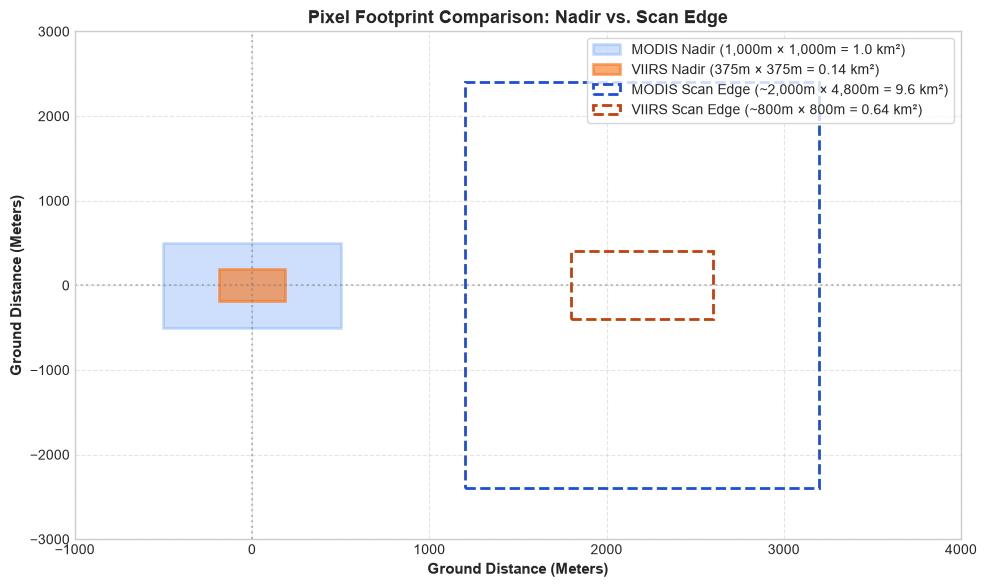

In [19]:
fig, ax = plt.subplots(figsize=(10, 6))

# MODIS nadir footprint (1000m x 1000m)
rect_modis_nadir = plt.Rectangle((-500, -500), 1000, 1000, linewidth=2, edgecolor='#3b82f6', facecolor='#3b82f6', alpha=0.25, label='MODIS Nadir (1,000m × 1,000m = 1.0 km²)')
# VIIRS nadir footprint (375m x 375m)
rect_viirs_nadir = plt.Rectangle((-187.5, -187.5), 375, 375, linewidth=2, edgecolor='#f97316', facecolor='#f97316', alpha=0.6, label='VIIRS Nadir (375m × 375m = 0.14 km²)')

# MODIS scan edge (2000m x 4800m)
rect_modis_edge = plt.Rectangle((1200, -2400), 2000, 4800, linewidth=2, edgecolor='#1d4ed8', facecolor='none', linestyle='--', label='MODIS Scan Edge (~2,000m × 4,800m = 9.6 km²)')
# VIIRS scan edge (800m x 800m)
rect_viirs_edge = plt.Rectangle((1800, -400), 800, 800, linewidth=2, edgecolor='#c2410c', facecolor='none', linestyle='--', label='VIIRS Scan Edge (~800m × 800m = 0.64 km²)')

ax.add_patch(rect_modis_nadir)
ax.add_patch(rect_viirs_nadir)
ax.add_patch(rect_modis_edge)
ax.add_patch(rect_viirs_edge)

ax.set_xlim(-1000, 4000)
ax.set_ylim(-3000, 3000)
ax.set_xlabel('Ground Distance (Meters)')
ax.set_ylabel('Ground Distance (Meters)')
ax.set_title('Pixel Footprint Comparison: Nadir vs. Scan Edge')
ax.axhline(0, color='gray', linestyle=':', alpha=0.5)
ax.axvline(0, color='gray', linestyle=':', alpha=0.5)
ax.legend(loc='upper right', frameon=True, facecolor='white')
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


---
## 10. Scientific Findings Taxonomy: Separating Observation from Hypothesis

To ensure scientific rigor, we structure our conclusions into a four-tier scientific taxonomy:
1. **Direct Observations:** Raw empirical facts directly measured.
2. **Statistical Descriptions:** Mathematical summaries across the catalog.
3. **Scientific Interpretations:** Physical explanations grounded in established literature.
4. **Hypotheses Requiring Further Investigation:** Plausible propositions that must be formally evaluated in Phase 4.

| # | Direct Observation | Statistical Description | Scientific Interpretation | Hypothesis Requiring Further Testing |
| :--- | :--- | :--- | :--- | :--- |
| **1** | VIIRS C2 catalog contains 18,466,561 valid records; MODIS C6.1 contains 3,708,771 valid records. | VIIRS-to-MODIS observation count ratio is **4.979x**. | Higher spatial resolution (375m vs 1000m) resolves sub-pixel fires that remain below the MODIS detection threshold (Giglio et al. 2016, Schroeder et al. 2014). Note that counts reflect active-fire observations rather than individual physical fires. | What proportion of the 4.979x ratio is due to spatial splitting of large fires vs. detecting isolated small fires? |
| **2** | MODIS mean FRP is 41.21 MW; VIIRS mean FRP is 9.68 MW. | MODIS mean is **4.25x** higher; MODIS median (17.9 MW) is **3.54x** higher than VIIRS (5.05 MW). | MODIS detects only fires radiating $\ge 8\text{--}10\text{ MW}$ in a 1km² pixel (Giglio et al. 2003, 2016); VIIRS detects low-intensity fires down to $\approx 0.5\text{--}1.0\text{ MW}$ (Schroeder et al. 2014). | Does aggregating adjacent VIIRS pixels into synthetic 1km footprints reconstruct the MODIS FRP distribution? |
| **3** | Sum of reported snapshot FRP is 152.82M MW for MODIS and 178.84M MW for VIIRS (+17.0%). | Total snapshot power sums differ by only 17.0% despite a 398% difference in detection counts. | Large fires radiate the majority of power and are captured by both sensors; small fires add many detections but little power. | Can cluster-level FRP integration provide consistent fire size classifications across both instruments? |
| **4** | UTC observations peak between 12:00 and 14:00 UTC; LST observations peak near 10:30 and 13:30. | 70.1% of observations occur during daytime passes; 29.9% occur at night. | Global UTC observation counts reflect satellite overpass timing and the geographic distribution of detections. Estimated Local Solar Time (~10:30 and ~13:30) provides a more useful approximation of local overpass timing, but neither distribution alone establishes the actual daily fire-occurrence cycle. | How much does diurnal sampling bias differ between polar-orbiting snapshots and continuous geostationary observations? |
| **5** | Exactly 9 records out of 22,175,341 are flagged invalid (1 negative FRP, 8 ST duplicates). | Dataset validity rate is **99.99996%**; 0 coordinate errors; 0 timestamp errors. | NASA FIRMS processing achieves high reliability. Negative FRP represents an empirical retrieval edge-case. | Could the 8 VIIRS duplicate records represent identical multi-granule overlap processing in FIRMS ingest? |

---
## 11. Candidate Starting Hypotheses for Phase 4 Harmonization

The empirical findings from this EDA provide starting parameters that must be **systematically tested and evaluated** in Phase 4:

### 11.1 Candidate Spatial Matching Radius ($R_{\text{match}} \approx 1.25\text{--}3.5\text{ km}$)
- *Hypothesis:* Because footprint area expands from nadir to scan edge, the spatial matching threshold should adapt dynamically based on view zenith angle:
  $$R_{\text{match}}(\theta) = \sqrt{R_{\text{MODIS}}^2(\theta) + R_{\text{VIIRS}}^2(\theta)}$$
- *Required Phase 4 Evaluation:* Must test sensitivity against fixed radii (500m, 1km, 1.5km, 2km) and quantify the rate of **false associations** (linking unrelated fires) versus **missed associations** (failing to link true co-observations).

### 11.2 Candidate Many-to-One ($N:1$) Association Architecture
- *Hypothesis:* Multiple VIIRS 375m detections overlap a single 1km MODIS footprint. An $N:1$ bipartite graph matches multiple VIIRS observations to one MODIS centroid.
- *Required Phase 4 Evaluation:* Must evaluate whether summing VIIRS FRP within the matching radius produces energetic agreement with the co-located MODIS FRP.

### 11.3 Candidate Temporal Gating Window ($\Delta t \le 90\text{ min}$)
- *Hypothesis:* Aqua and NOAA-20 cross the equator within $\approx 15\text{ minutes}$ of each other (both near 13:30 local solar time), representing true near-simultaneous observations. Cross-overs between Terra (10:30) and NOAA-20 (13:30) represent diurnal progression ($\Delta t \approx 3\text{ hours}$).
- *Required Phase 4 Evaluation:* Evaluate separate matching thresholds for same-orbit-plane co-observations ($\Delta t \le 30\text{ min}$) versus cross-orbit diurnal tracking ($\Delta t \le 180\text{ min}$).

*Explicit Constraint:* Phase 4 matching engine will be implemented in the subsequent phase.

---
## 12. Reusable Analytical Outputs Generator

The cell below provides an automated generator that can refresh all eight precomputed analytical artifacts in `data/analytics/` directly from the unified catalog without altering raw NASA datasets.

These artifacts power the FireLens FastAPI backend and the React dashboard:
```text
Unified Catalog (22.18M rows)
       │
       ▼ [DuckDB Columnar Aggregations]
data/analytics/
  ├── analytics_summary.json       ──► GET /api/analytics/overview
  ├── temporal_summary.json        ──► GET /api/analytics/temporal
  ├── monthly_statistics.csv       ──► Tabular Monthly Exports
  ├── daily_distribution.csv       ──► 365-Day Daily Time-Series
  ├── hourly_distribution.csv      ──► Diurnal Cycle Aggregation
  ├── frp_statistics.json          ──► GET /api/analytics/frp
  ├── geographical_grid_density.csv──► GET /api/analytics/grid-density
  └── sensor_comparison.json       ──► GET /api/analytics/sensor-comparison
```

In [20]:
def refresh_analytics_artifacts():
    '''Regenerates all eight analytical artifacts in data/analytics/.'''
    out_dir = DATA_DIR / "analytics"
    out_dir.mkdir(parents=True, exist_ok=True)
    t_start = time.time()
    print(f"Refreshing analytical artifacts in {out_dir}...")

    # 1. Monthly Statistics
    monthly_df = con.execute('''
        SELECT 
            strftime(cast(acquisition_date as date), '%Y-%m') as month,
            SUM(CASE WHEN instrument = 'MODIS' THEN 1 ELSE 0 END) as modis_count,
            SUM(CASE WHEN instrument = 'VIIRS' THEN 1 ELSE 0 END) as viirs_count,
            COUNT(*) as total_count,
            ROUND(AVG(CASE WHEN instrument = 'MODIS' THEN frp ELSE NULL END), 2) as modis_mean_frp,
            ROUND(AVG(CASE WHEN instrument = 'VIIRS' THEN frp ELSE NULL END), 2) as viirs_mean_frp,
            ROUND(SUM(CASE WHEN instrument = 'MODIS' THEN frp ELSE 0 END), 2) as modis_total_frp,
            ROUND(SUM(CASE WHEN instrument = 'VIIRS' THEN frp ELSE 0 END), 2) as viirs_total_frp,
            ROUND(SUM(frp), 2) as total_frp
        FROM unified
        WHERE is_valid = true
        GROUP BY month
        ORDER BY month
    ''').df()
    monthly_df.to_csv(out_dir / "monthly_statistics.csv", index=False)

    # 2. Daily Distribution
    daily_df = con.execute('''
        SELECT 
            cast(acquisition_date as date) as acquisition_date,
            SUM(CASE WHEN instrument = 'MODIS' THEN 1 ELSE 0 END) as modis_count,
            SUM(CASE WHEN instrument = 'VIIRS' THEN 1 ELSE 0 END) as viirs_count,
            COUNT(*) as total_count,
            ROUND(SUM(frp), 2) as total_frp
        FROM unified
        WHERE is_valid = true
        GROUP BY acquisition_date
        ORDER BY acquisition_date
    ''').df()
    daily_df.to_csv(out_dir / "daily_distribution.csv", index=False)

    # 3. Hourly Distribution
    hourly_df = con.execute('''
        SELECT 
            CAST(extract(hour from acquisition_time) AS INTEGER) as hour_utc,
            SUM(CASE WHEN instrument = 'MODIS' THEN 1 ELSE 0 END) as modis_count,
            SUM(CASE WHEN instrument = 'VIIRS' THEN 1 ELSE 0 END) as viirs_count,
            COUNT(*) as total_count
        FROM unified
        WHERE is_valid = true AND acquisition_time IS NOT NULL
        GROUP BY hour_utc
        ORDER BY hour_utc
    ''').df()
    hourly_df.to_csv(out_dir / "hourly_distribution.csv", index=False)

    # 4. Geographical Grid Density (2-degree grid)
    grid_df = con.execute('''
        SELECT 
            CAST(FLOOR(latitude / 2.0) * 2.0 AS DOUBLE) as lat_bin,
            CAST(FLOOR(longitude / 2.0) * 2.0 AS DOUBLE) as lon_bin,
            SUM(CASE WHEN instrument = 'MODIS' THEN 1 ELSE 0 END) as modis_count,
            SUM(CASE WHEN instrument = 'VIIRS' THEN 1 ELSE 0 END) as viirs_count,
            COUNT(*) as total_count,
            ROUND(AVG(frp), 2) as mean_frp,
            ROUND(SUM(frp), 2) as total_frp
        FROM unified
        WHERE is_valid = true
        GROUP BY lat_bin, lon_bin
        ORDER BY total_count DESC
    ''').df()
    grid_df.to_csv(out_dir / "geographical_grid_density.csv", index=False)

    # 5. Temporal Summary JSON
    dow_df = con.execute('''
        SELECT 
            strftime(cast(acquisition_date as date), '%A') as day_name,
            extract(dow from cast(acquisition_date as date)) as dow_index,
            SUM(CASE WHEN instrument = 'MODIS' THEN 1 ELSE 0 END) as modis_count,
            SUM(CASE WHEN instrument = 'VIIRS' THEN 1 ELSE 0 END) as viirs_count,
            COUNT(*) as total_count
        FROM unified
        WHERE is_valid = true
        GROUP BY day_name, dow_index
        ORDER BY dow_index
    ''').df()

    dn_df = con.execute('''
        SELECT 
            instrument,
            daynight,
            COUNT(*) as count
        FROM unified
        WHERE is_valid = true
        GROUP BY instrument, daynight
    ''').fetchall()

    dn_map = {'MODIS': {}, 'VIIRS': {}}
    for inst, dn, cnt in dn_df:
        if inst in dn_map:
            dn_map[inst][dn] = cnt

    temporal_summary = {
        "generated_at": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
        "monthly": monthly_df.to_dict(orient="records"),
        "hourly": hourly_df.to_dict(orient="records"),
        "day_of_week": dow_df.to_dict(orient="records"),
        "day_night": {
            "modis": {
                "day_count": dn_map['MODIS'].get('D', 0),
                "night_count": dn_map['MODIS'].get('N', 0),
                "day_percentage": round(dn_map['MODIS'].get('D', 0) / max(1, sum(dn_map['MODIS'].values())) * 100, 2),
                "night_percentage": round(dn_map['MODIS'].get('N', 0) / max(1, sum(dn_map['MODIS'].values())) * 100, 2),
            },
            "viirs": {
                "day_count": dn_map['VIIRS'].get('D', 0),
                "night_count": dn_map['VIIRS'].get('N', 0),
                "day_percentage": round(dn_map['VIIRS'].get('D', 0) / max(1, sum(dn_map['VIIRS'].values())) * 100, 2),
                "night_percentage": round(dn_map['VIIRS'].get('N', 0) / max(1, sum(dn_map['VIIRS'].values())) * 100, 2),
            }
        }
    }
    # Custom JSON serializer for numpy types
    def np_encoder(o):
        if isinstance(o, (np.integer, np.int64, np.int32)):
            return int(o)
        if isinstance(o, (np.floating, np.float64, np.float32)):
            return float(o)
        return str(o)

    with open(out_dir / "temporal_summary.json", "w") as f:
        json.dump(temporal_summary, f, indent=2, default=np_encoder)

    # 6. FRP Statistics JSON
    frp_all = con.execute('''
        SELECT 
            ROUND(MIN(frp), 2), ROUND(MAX(frp), 2), ROUND(AVG(frp), 2), ROUND(STDDEV_SAMP(frp), 2),
            ROUND(MEDIAN(frp), 2), ROUND(QUANTILE_CONT(frp, 0.25), 2), ROUND(QUANTILE_CONT(frp, 0.75), 2),
            ROUND(QUANTILE_CONT(frp, 0.95), 2), ROUND(QUANTILE_CONT(frp, 0.99), 2), ROUND(SUM(frp), 2), COUNT(*)
        FROM unified WHERE is_valid = true AND frp >= 0
    ''').fetchone()

    frp_m = con.execute('''
        SELECT 
            ROUND(MIN(frp), 2), ROUND(MAX(frp), 2), ROUND(AVG(frp), 2), ROUND(STDDEV_SAMP(frp), 2),
            ROUND(MEDIAN(frp), 2), ROUND(QUANTILE_CONT(frp, 0.25), 2), ROUND(QUANTILE_CONT(frp, 0.75), 2),
            ROUND(QUANTILE_CONT(frp, 0.95), 2), ROUND(QUANTILE_CONT(frp, 0.99), 2), ROUND(SUM(frp), 2), COUNT(*)
        FROM unified WHERE instrument = 'MODIS' AND is_valid = true AND frp >= 0
    ''').fetchone()

    frp_v = con.execute('''
        SELECT 
            ROUND(MIN(frp), 2), ROUND(MAX(frp), 2), ROUND(AVG(frp), 2), ROUND(STDDEV_SAMP(frp), 2),
            ROUND(MEDIAN(frp), 2), ROUND(QUANTILE_CONT(frp, 0.25), 2), ROUND(QUANTILE_CONT(frp, 0.75), 2),
            ROUND(QUANTILE_CONT(frp, 0.95), 2), ROUND(QUANTILE_CONT(frp, 0.99), 2), ROUND(SUM(frp), 2), COUNT(*)
        FROM unified WHERE instrument = 'VIIRS' AND is_valid = true AND frp >= 0
    ''').fetchone()

    def map_stat(r):
        return {"min": r[0], "max": r[1], "mean": r[2], "std": r[3], "median": r[4], "q25": r[5], "q75": r[6], "q95": r[7], "q99": r[8], "total_mw": r[9], "count": r[10]}

    hist_rows = con.execute('''
        SELECT 
            CASE 
                WHEN frp < 5 THEN '0-5' WHEN frp < 10 THEN '5-10' WHEN frp < 25 THEN '10-25'
                WHEN frp < 50 THEN '25-50' WHEN frp < 100 THEN '50-100' WHEN frp < 250 THEN '100-250'
                WHEN frp < 500 THEN '250-500' WHEN frp < 1000 THEN '500-1000' ELSE '1000+'
            END as bin_label,
            CASE 
                WHEN frp < 5 THEN 1 WHEN frp < 10 THEN 2 WHEN frp < 25 THEN 3 WHEN frp < 50 THEN 4
                WHEN frp < 100 THEN 5 WHEN frp < 250 THEN 6 WHEN frp < 500 THEN 7 WHEN frp < 1000 THEN 8 ELSE 9
            END as bin_order,
            SUM(CASE WHEN instrument = 'MODIS' THEN 1 ELSE 0 END) as modis_count,
            SUM(CASE WHEN instrument = 'VIIRS' THEN 1 ELSE 0 END) as viirs_count,
            COUNT(*) as total_count
        FROM unified WHERE is_valid = true AND frp >= 0
        GROUP BY bin_label, bin_order ORDER BY bin_order
    ''').df().to_dict(orient="records")

    frp_statistics = {
        "generated_at": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
        "overall": map_stat(frp_all),
        "modis": map_stat(frp_m),
        "viirs": map_stat(frp_v),
        "histogram": hist_rows
    }
    with open(out_dir / "frp_statistics.json", "w") as f:
        json.dump(frp_statistics, f, indent=2, default=np_encoder)

    # 7. Sensor Comparison JSON
    sensor_comparison = {
        "generated_at": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
        "observations": {
            "modis_count": int(frp_m[10]), "viirs_count": int(frp_v[10]), "total_count": int(frp_m[10] + frp_v[10]),
            "viirs_to_modis_ratio": round(float(frp_v[10]) / max(1, float(frp_m[10])), 3),
            "modis_percentage": round(float(frp_m[10]) / (float(frp_m[10]) + float(frp_v[10])) * 100, 2),
            "viirs_percentage": round(float(frp_v[10]) / (float(frp_m[10]) + float(frp_v[10])) * 100, 2)
        },
        "spatial_resolution": {"modis_nadir_resolution_m": 1000, "viirs_nadir_resolution_m": 375, "pixel_area_ratio_nadir": 7.11},
        "frp_comparison": {
            "modis_mean_mw": float(frp_m[2]), "viirs_mean_mw": float(frp_v[2]), "ratio_mean_frp": round(float(frp_m[2]) / max(0.01, float(frp_v[2])), 2),
            "modis_median_mw": float(frp_m[4]), "viirs_median_mw": float(frp_v[4]), 
            "modis_sum_reported_mw": float(frp_m[9]), "viirs_sum_reported_mw": float(frp_v[9]),
            "modis_total_mw": float(frp_m[9]), "viirs_total_mw": float(frp_v[9]),
            "total_frp_ratio_viirs_to_modis": round(float(frp_v[9]) / max(0.01, float(frp_m[9])), 2)
        },
        "confidence_distribution": {
            "modis": {"type": "numeric_percentage_0_100", "analyst_defined_bins_disclaimer": "Analyst-defined exploratory categories, not equivalent to VIIRS flags"},
            "viirs": {"type": "categorical_flags_l_n_h"}
        },
        "day_night_comparison": temporal_summary["day_night"],
        "orbital_parameters": {
            "modis": {"platforms": ["Terra", "Aqua"], "equator_crossing_terra": "10:30 Descending / 22:30 Ascending", "equator_crossing_aqua": "13:30 Ascending / 01:30 Descending"},
            "viirs": {"platforms": ["NOAA-20 (JPSS-1)"], "equator_crossing": "13:30 Ascending / 01:30 Descending"}
        },
        "scientific_reasons_for_divergence": [
            "Spatial resolution advantage (375m vs 1000m): VIIRS resolves sub-pixel fires that MODIS misses due to thermal dilution in 1km² pixels (Giglio et al. 2016, Schroeder et al. 2014).",
            "Edge-of-scan pixel geometry: VIIRS onboard pixel aggregation constrains pixel growth to ~4x vs MODIS ~10x expansion (Wolfe et al. 2002, Schroeder et al. 2014).",
            "Swath width difference: VIIRS 3040 km swath leaves no equatorial gaps, while MODIS (2330 km) has daytime orbital gaps.",
            "Detection threshold: Minimum detectable FRP for VIIRS is ~0.5-1.0 MW compared to ~8-10 MW for MODIS (Schroeder et al. 2014, Giglio et al. 2003, 2016)."
        ]
    }
    with open(out_dir / "sensor_comparison.json", "w") as f:
        json.dump(sensor_comparison, f, indent=2, default=np_encoder)

    # 8. Analytics Summary JSON
    analytics_summary = {
        "generated_at": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
        "dataset_provenance": "NASA FIRMS (Fire Information for Resource Management System)",
        "temporal_coverage": {"start_date": "2025-01-01", "end_date": "2025-12-31", "year": 2025},
        "counts": {
            "total_observations": int(total_all), "valid_observations": int(valid_all), "invalid_observations": int(invalid_all),
            "modis_count": int(frp_m[10]), "viirs_count": int(frp_v[10]), "viirs_to_modis_ratio": round(float(frp_v[10]) / max(1, float(frp_m[10])), 3)
        },
        "frp_aggregates": {
            "sum_reported_frp_mw": float(frp_all[9]), "total_frp_mw": float(frp_all[9]), "mean_frp_mw": float(frp_all[2]),
            "modis_sum_mw": float(frp_m[9]), "modis_total_mw": float(frp_m[9]),
            "viirs_sum_mw": float(frp_v[9]), "viirs_total_mw": float(frp_v[9]),
            "modis_mean_mw": float(frp_m[2]), "viirs_mean_mw": float(frp_v[2])
        },
        "energetics": {  # Deprecated alias for backwards compatibility
            "total_frp_mw": float(frp_all[9]), "mean_frp_mw": float(frp_all[2]), "modis_total_mw": float(frp_m[9]), "viirs_total_mw": float(frp_v[9]),
            "modis_mean_mw": float(frp_m[2]), "viirs_mean_mw": float(frp_v[2])
        },
        "geographical_extent": {"min_latitude": -90.0, "max_latitude": 90.0, "min_longitude": -180.0, "max_longitude": 180.0, "total_active_grid_cells": len(grid_df)},
        "key_findings": [
            f"VIIRS detects {round(float(frp_v[10]) / max(1, float(frp_m[10])), 3)}x more active-fire observations than MODIS (18.47M vs 3.71M), driven by its 375m spatial resolution.",
            "MODIS records a significantly higher mean FRP (41.21 MW vs 9.68 MW) because smaller, cooler fires remain below the 1km MODIS detection threshold.",
            "Sum of reported snapshot FRP observations is 152.8M MW for MODIS vs 178.8M MW for VIIRS (+17%), reflecting differing pixel aggregation and detection sensitivity rather than continuous energy convergence.",
            "Global UTC observation counts reflect satellite overpass timing and the geographic distribution of detections. Estimated Local Solar Time (~10:30 and ~13:30) provides a more useful approximation of local overpass timing, but neither distribution alone establishes the actual daily fire-occurrence cycle.",
            "Data quality is exceptional: 22,175,332 out of 22,175,341 records (>99.9999%) are valid with zero missing coordinates or corrupt timestamps."
        ]
    }
    with open(out_dir / "analytics_summary.json", "w") as f:
        json.dump(analytics_summary, f, indent=2, default=np_encoder)

    elapsed = time.time() - t_start
    print(f"All eight analytical artifacts successfully refreshed in {elapsed:.2f} seconds!")

# Execute generator
refresh_analytics_artifacts()


Refreshing analytical artifacts in D:\user\Documents\nasa\data\analytics...


All eight analytical artifacts successfully refreshed in 59.83 seconds!


---
## 13. Scientific References & Documentation

1. **Giglio, L., Schroeder, W., & Justice, C. O. (2016).** The collection 6 MODIS active fire detection algorithm and fire products. *Remote Sensing of Environment*, 178, 31–41.
2. **Giglio, L., Descloitres, J., Justice, C. O., & Kaufman, Y. J. (2003).** An enhanced contextual fire detection algorithm for MODIS. *Remote Sensing of Environment*, 87(2-3), 273–282.
3. **Schroeder, W., Oliva, P., Giglio, L., & Csiszar, I. A. (2014).** The New VIIRS 375 m active fire detection product—Algorithm description and initial assessment. *Remote Sensing of Environment*, 143, 85–96.
4. **Wolfe, R. E., Nishihama, M., Fleig, A. J., Kuyper, J. A., Roy, D. P., Storey, J. C., & Patt, F. S. (2002).** Achieving sub-pixel geolocation accuracy in support of MODIS land science. *Remote Sensing of Environment*, 83(1-2), 31–49.
5. **Wooster, M. J., Zhukov, B., & Oertel, D. (2003).** Fire radiative energy for quantitative study of biomass burning: derivation from the BIRD experimental satellite and comparison to MODIS fire products. *Remote Sensing of Environment*, 86(1), 83–107.
6. **Wooster, M. J., Roberts, G., Perry, G. L. W., & Kaufman, Y. J. (2005).** Retrieval of biomass combustion rates and totals from fire radiative power observations: FRP derivation and calibration relationships. *Journal of Geophysical Research: Atmospheres*, 110(D24).
7. **Kaufman, Y. J., Justice, C. O., Flynn, L. P., Kendall, J. D., Prins, E. M., Giglio, L., Ward, D. E., Menzel, W. P., & Setzer, A. W. (1998).** Potential global fire monitoring from EOS-MODIS. *Journal of Geophysical Research: Atmospheres*, 103(D24), 32215–32238.
8. **NASA FIRMS (Fire Information for Resource Management System).** *MODIS and VIIRS Fire and Thermal Anomalies Product Documentation*. NASA Earthdata / LANCE. https://firms.modaps.eosdis.nasa.gov/

---
**End of Scientific Analysis — FireLens Phase 3.2 Deliverable**

4. **Wooster, M. J., Roberts, G., Perry, G. L. W., & Kaufman, Y. J. (2005).** Retrieval of biomass combustion rates and totals from fire radiative power observations: FRP derivation and calibration relationships. *Journal of Geophysical Research: Atmospheres*, 110(D24).
5. **Kaufman, Y. J., Justice, C. O., Flynn, L. P., Kendall, J. D., Prins, E. M., Giglio, L., Ward, D. E., Menzel, W. P., & Setzer, A. W. (1998).** Potential global fire monitoring from EOS-MODIS. *Journal of Geophysical Research: Atmospheres*, 103(D24), 32215–32238.
6. **NASA FIRMS (Fire Information for Resource Management System).** *MODIS and VIIRS Fire and Thermal Anomalies Product Documentation*. NASA Earthdata / LANCE. https://firms.modaps.eosdis.nasa.gov/

---
**End of Scientific Analysis — FireLens Phase 3.1 Deliverable**
